# Capstone Project: Building Machine Learning Model
## Study Case: Hotel Booking

##### Notice:
The dataset used in this analysis is a dummy dataset. It doesn't contain actual, sensitive, and real business data.

### Business Problem Understanding

#### Context

This hotel was established in July 2018, located in Lagos, Algarve Region, Portugal. The hotel is assigned as 4-star hotel.\
In year 2025, based on Government Statistics, Occupany Rate for the region was 61.4% for year 2025.
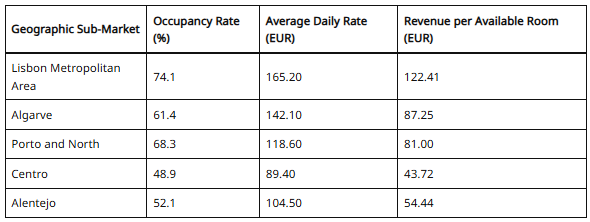\
Source: https://thehotelblueprint.com/hotel-market-intel/hotel-performance/portugal-full-year-2025/

#### Problem Statement

The hotel accepts thousands of reservations each year. Within those reservations, there are a lot of cancelation from the hotel guests. This will affect hotel's daily occupancy rate, as the room can not be sold for the day because hotel do not receive any confirmation before D-day.

**Stakeholder:**\
General Manager decide to find a way on how to predict guest bookings, which are likely to be canceled.

#### Analytic Approach

**Prediction outcome:**
* Guests who will cancel their bookings
* Guests who will not cancel their bookings

To predict the outcome, Machine Learning Classification algorithm will be used.

#### Metric Evaluation

| Condition | Impact |
| -- | -- |
| False Positive | Guests that are falsely predicted to cancel their hotel bookings.<br> If we do not accept these reservations, we will suffer from loss in revenue and greater loss in trust from the hotel guests. There is a possibility this guest will not make future bookings anymore. |
| False Negative | Guests that are falsely predicted to stay, but they cancel their hotel bookings or no-show on that day.<br>All the prepared-rooms will become vacant. This will cause low occupany rate of the day, and in longer terms will affect future potential investors decision, whether they should invest or not in a hotel with 'low occupancy rate'. Only if they confirmed and cancel their booking before D-Day, the room can be sold to another guests. |

Daily occupany rate is calculated based on **the actual number of rooms** occupied by guests. Even the guests booked the room, but do not stay for the night, it will not be counted; lowering the occupany rate.
<center><b>Occupancy Rate = (Number of Occupied Units / Total Number of Available Units) x 100%</b></center>

<br>Choosing a best metric to evaluate the model, will depend on the hotel's business model.\
If the hotel is affiliated with a hotel chain program (e.g. IHG, Accor, Conrad), they will value "trust" from the hotel guests the most. Hence, the model should focus on lowering the 'False Positive' rate.\
If the hotel is non-affiliated and have high daily occupany rate most of the time, they will need a model who can predict guests that will likely to cancel their bookings. So, they can resell the room to another guests. With this business model, the hotel will focus on lowering the 'False Negative' rate. Furthermore, this is also applied if the hotel's owner want to attract new investors.

Each model designed specifically to each business model.\
Considering the dataset is not provided with "Date" column and daily occupancy rate is unknown,\
this model will focus on predicting "Who are the hotel guests that will likely to cancel their bookings" with **Low False Positive Rate**.\
Therefore, the F-score (beta = 0.5) will be used.

Another thing to consider, we want our model to predict hotel guests who will cancel. We do not want to falsely predict "True Staying hotel guest". If we falsely predict (False Positive), this will create another issue. We will lose their trust, and there's possibility they will not book again in the future (Churn). 

### Data Understanding

**Features:**\
*All personally identifying information has been removed from the data.*

| Features | Description |
| -- | -- |
| country| Country of guests origin. |
| market_segment | Market segment designation. |
| previous_cancellations | Number of previous bookings that were cancelled by the customer prior to the current booking. |
| booking_changes | Number of changes/amendments made to the booking from the moment the booking was entered on the PMS until the moment of check-in or cancellation. |
| deposit_type | Indication on if the customer made a deposit to guarantee the booking. |
| days_in_waiting_list | Number of days the booking was in the waiting list before it was confirmed to the customer. |
| customer_type | Type of booking. |
| reserved_room_type | Code of room type reserved. Code is presented instead of designation for anonymity reasons. |
| required_car_parking_space | Number of car parking spaces required by the customer. |
| total_of_special_request | Number of special requests made by the customer (e.g. twin bed or high floor). |
| is_canceled | Value indicating if the booking was canceled (1) or not (0). |


In [1]:
# Import Library
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import math

In [2]:
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_columns', None)
from IPython.display import display, HTML
from IPython.display import display_html

In [70]:
path = ''

In [4]:
df = pd.read_csv(path + 'data_hotel_booking_demand.csv')
df.head()

,country,market_segment,previous_cancellations,booking_changes,deposit_type,days_in_waiting_list,customer_type,reserved_room_type,required_car_parking_spaces,total_of_special_requests,is_canceled
0,IRL,Offline TA/TO,0,0,No Deposit,0,Transient-Party,A,0,0,0
1,FRA,Online TA,0,0,No Deposit,0,Transient,A,0,2,0
2,PRT,Online TA,0,1,No Deposit,0,Transient,A,0,2,0
3,NLD,Online TA,0,0,No Deposit,0,Transient,A,0,1,1
4,PRT,Online TA,0,2,No Deposit,0,Transient,A,0,2,0


In [5]:
print('df Shape:' , df.shape,'\n')
# As PII (Personal Identifying Information) has been removed; and Booking ID/Number are not provided, duplicates of the dataset can't be checked
print(df.columns,'\n')
print('Null rows: ', df.isna().sum(),'\n')
print(df.info())

df Shape: (83573, 11) 

Index(['country', 'market_segment', 'previous_cancellations',
       'booking_changes', 'deposit_type', 'days_in_waiting_list',
       'customer_type', 'reserved_room_type', 'required_car_parking_spaces',
       'total_of_special_requests', 'is_canceled'],
      dtype='str') 

Null rows:  country                        351
market_segment                   0
previous_cancellations           0
booking_changes                  0
deposit_type                     0
days_in_waiting_list             0
customer_type                    0
reserved_room_type               0
required_car_parking_spaces      0
total_of_special_requests        0
is_canceled                      0
dtype: int64 

<class 'pandas.DataFrame'>
RangeIndex: 83573 entries, 0 to 83572
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   country                      83222 non-null  str  
 1   market_segment 

Assumption: The dataset was extracted from data collected during the year 2025.

In [6]:
#Unique Values from Dataset
Unique_Dict = {
    'columns' : [],
    'unique_count' : [],
    'unique' : [],
    'dtype' : []
}

for idx in range( len(df.columns) ) :
    Unique_Dict['columns'].append(df.columns[idx])
    Unique_Dict['unique_count'].append(df[df.columns[idx]].nunique())
    if (df[df.columns[idx]].nunique()) < 20:
        Unique_Dict['unique'].append(df[df.columns[idx]].unique())
    else:
        Unique_Dict['unique'].append('More than 20')
    Unique_Dict['dtype'].append(df.dtypes.iloc[idx])

pd.DataFrame(Unique_Dict)

,columns,unique_count,unique,dtype
0,country,162,More than 20,str
1,market_segment,8,"[Offline TA/TO, Online TA, Direct, Groups, Corporate, Complementary, Aviation, Undefined]",str
2,previous_cancellations,15,"[0, 1, 25, 2, 3, 11, 24, 13, 6, 26, 14, 4, 19, 5, 21]",int64
3,booking_changes,19,"[0, 1, 2, 5, 3, 4, 6, 7, 9, 8, 17, 10, 13, 12, 14, 21, 16, 20, 15]",int64
4,deposit_type,3,"[No Deposit, Non Refund, Refundable]",str
5,days_in_waiting_list,115,More than 20,int64
6,customer_type,4,"[Transient-Party, Transient, Contract, Group]",str
7,reserved_room_type,10,"[A, E, D, F, B, G, C, H, L, P]",str
8,required_car_parking_spaces,5,"[0, 1, 2, 8, 3]",int64
9,total_of_special_requests,6,"[0, 2, 1, 3, 4, 5]",int64


**Description of Unique Values of Categorical Features**

| Features | Unique Values | Description |
| -- | -- | -- |
| market_segment | Offline TA/TO | Offline Travel Agent/Travel Organizer |
|   | Online TA | Online Travel Agent |
|   | Direct | Direct booking to the hotel |
|   | Groups | Reservation for multiple rooms made by individuals |
|   | Corporate | Booking from Corporation |
|   | Complementary | Guests who receive complimentary stay |
|   | Aviation | Booking from airlines: air-crew members, passengers (due to layovers, reschedule, etc.) |
|   | Undefined | Missing values |
| deposit_type | Non Deposit | Booking made without payment and deposit |
|   | Non Refund | Booking has been made, paid deposit without refund option |
|   | Refundable | Booking has been made, paid deposit with refund option |
| customer_type | Transient | Individual bookings |
|   | Transient-party | Individual bookings with multiple rooms |
|   | Contract | Bookings made with pre-signed contract, usually from individuals or corporate **for specific event** |
|   | Group | Bookings made with pre-signed long-term contract, usually from airlines, corporates, travel organizer |
| reserved_room_type | A,B,C,D,E,F,G,H,L,P | Code of room type reserved. Generally, room types that usually offered are Superior, Deluxe, Junior Suite, etc. But, for each room types, hotel distinguish between double bed (further breakdown: standard, queen, king bed) and twin bed.<br>These room types can not be ranked in order. |
| total_of_special_request | Various | Special requests are usually including, but not limited to: type of beds, floor location, room view, early/late check-in/check-out, room decoration, quiet room, room location (close to the elevator), smoking/non-smoking room. |


### Exploratory Data Analysis (EDA)

In [7]:
# Color palette for graph
Canceled_T = 'crimson'
Canceled_F = 'moccasin'
Canceled_color = {0:Canceled_F, 1:Canceled_T}

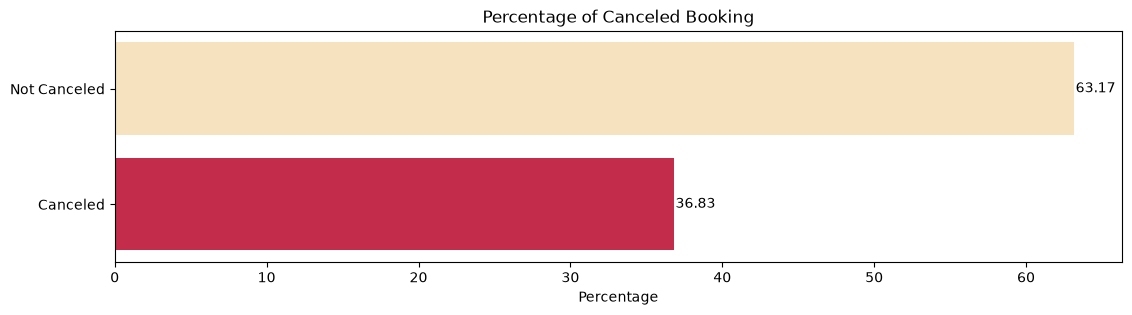

In [8]:
# Percentage of Canceled Booking from Dataset

plt.figure(figsize=(13,3))
ax = sns.countplot(data=df, y='is_canceled', stat='percent', hue='is_canceled', palette=Canceled_color, legend=False)
ax.set_title('Percentage of Canceled Booking')
ax.set_ylabel('')
ax.set_xlabel('Percentage')
plt.yticks(ticks=[0,1], labels=['Not Canceled', 'Canceled'])

# Bar Annotation
for container in ax.containers:
  ax.bar_label(container, fmt="%.2f", label_type="edge", color='black', padding=1)


With 63% vs 37%, this dataset can be considered as balanced. To improve the model later, resampling method will be conducted.

In [9]:
df.describe()

,previous_cancellations,booking_changes,days_in_waiting_list,required_car_parking_spaces,total_of_special_requests,is_canceled
count,83573.000000,83573.000000,83573.000000,83573.000000,83573.000000,83573.000000
mean,0.086798,0.220897,2.330561,0.062999,0.573211,0.368277
std,0.841011,0.648635,17.673051,0.246919,0.795163,0.482340
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000
max,26.000000,21.000000,391.000000,8.000000,5.000000,1.000000


In [10]:
# Descriptive Statistic for each Class (Not Canceled vs Canceled Bookings)

df_0 = df[df['is_canceled']==0][['previous_cancellations','booking_changes', 'days_in_waiting_list', 'required_car_parking_spaces',
       'total_of_special_requests']].describe().T

df_1 = df[df['is_canceled']==1][['previous_cancellations','booking_changes', 'days_in_waiting_list', 'required_car_parking_spaces',
       'total_of_special_requests']].describe().T

df_0 = df_0.style.set_table_attributes("style='display:inline; margin-right:40px;'").set_caption('Non Canceled Bookings')
df_1 = df_1.style.set_table_attributes("style='display:inline;'").set_caption('Canceled Bookings')

display_html(df_0._repr_html_() + df_1._repr_html_() , raw=True)

,count,mean,std,min,25%,50%,75%,max
previous_cancellations,52795.000000,0.016422,0.286676,0.000000,0.000000,0.000000,0.000000,13.000000
booking_changes,52795.000000,0.293077,0.733008,0.000000,0.000000,0.000000,0.000000,21.000000
days_in_waiting_list,52795.000000,1.572175,14.781696,0.000000,0.000000,0.000000,0.000000,379.000000
required_car_parking_spaces,52795.000000,0.099725,0.304714,0.000000,0.000000,0.000000,0.000000,8.000000
total_of_special_requests,52795.000000,0.716488,0.837029,0.000000,0.000000,1.000000,1.000000,5.000000
,count,mean,std,min,25%,50%,75%,max
previous_cancellations,30778.000000,0.207518,1.325352,0.000000,0.000000,0.000000,0.000000,26.000000
booking_changes,30778.000000,0.097082,0.443292,0.000000,0.000000,0.000000,0.000000,16.000000
days_in_waiting_list,30778.000000,3.631458,21.694131,0.000000,0.000000,0.000000,0.000000,391.000000
required_car_parking_spaces,30778.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


##### Previous Cancelation

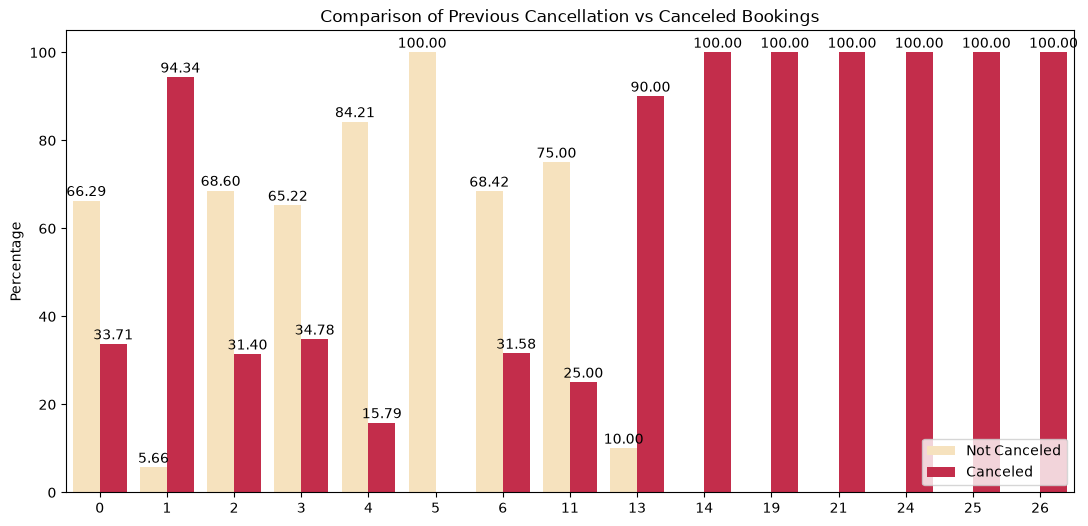

In [11]:
# Previous Cancelation vs Canceled Bookings

df_Seg = df.groupby(['previous_cancellations', 'is_canceled'],as_index=False)['customer_type'].count()
df_Seg = df_Seg.rename(columns={'customer_type':'Count'})

df_Sub = df.groupby('previous_cancellations',as_index=False)[['customer_type']].count()
df_Sub = df_Sub.rename(columns={'customer_type':'Total'})

df_Seg = df_Seg.merge(right=df_Sub[['previous_cancellations', 'Total']], how='outer')

df_Seg['Percentage'] = round ( df_Seg['Count'] / df_Seg['Total'] * 100 , 2)
df_Seg = df_Seg.sort_values(by=['Total'],ascending=[False]).reset_index(drop=True)

################################################

plt.figure(figsize=(13,6))
ax = sns.barplot(data=df_Seg, x='previous_cancellations', y='Percentage', hue='is_canceled', palette=Canceled_color)
ax.set_title('Comparison of Previous Cancellation vs Canceled Bookings')
ax.set_xlabel('')
ax.set_ylabel('Percentage')

# Bar Annotation
for container in ax.containers:
  ax.bar_label(container, fmt="%.2f", label_type="edge", color='black', padding=1)

handles, labels = ax.get_legend_handles_labels()
new_labels = ['Not Canceled', 'Canceled']

ax.legend(handles=handles, labels=new_labels, title='', loc='lower right')


In [12]:
# 13 is selected, percentage is rounded number (and to isolate the rest 14-26 with 100% cancelation rate)
df[df['previous_cancellations']==13]

,country,market_segment,previous_cancellations,booking_changes,deposit_type,days_in_waiting_list,customer_type,reserved_room_type,required_car_parking_spaces,total_of_special_requests,is_canceled
2603,PRT,Offline TA/TO,13,0,No Deposit,31,Transient-Party,A,0,0,1
13984,PRT,Groups,13,0,No Deposit,31,Transient-Party,A,0,0,1
17300,PRT,Offline TA/TO,13,0,No Deposit,31,Transient-Party,A,0,0,1
24118,FRA,Direct,13,1,No Deposit,0,Transient,D,0,0,0
37105,PRT,Groups,13,0,No Deposit,31,Transient-Party,A,0,0,1
45754,PRT,Groups,13,0,No Deposit,31,Transient-Party,A,0,0,1
48227,PRT,Groups,13,0,No Deposit,31,Transient-Party,A,0,0,1
58939,PRT,Offline TA/TO,13,0,No Deposit,31,Transient-Party,A,0,0,1
66584,PRT,Groups,13,0,No Deposit,31,Transient-Party,A,0,0,1
72834,PRT,Offline TA/TO,13,0,No Deposit,31,Transient-Party,A,0,0,1


Cancellations will be binned to isolate significant difference:\
1 No Cancel; 2 Cancel 1 time; 3 Cancel 2-13 times; 4 Cancel 14 times and above

In [13]:
# Binned Cancellations

df_0 = df[df['previous_cancellations']==0].groupby(['is_canceled'],as_index=False)['market_segment'].count()
df_0 = df_0.rename(columns={'market_segment':'Count'})
df_0['Percentage'] =  round ( df_0['Count'] / len(df[df['previous_cancellations']==0]) * 100 , 2)
df_0['Num_Cancel'] = 'Cancel_Zero'

df_1 = df[df['previous_cancellations']==1].groupby(['is_canceled'],as_index=False)['market_segment'].count()
df_1 = df_1.rename(columns={'market_segment':'Count'})
df_1['Percentage'] =  round ( df_1['Count'] / len(df[df['previous_cancellations']==1]) * 100 , 2)
df_1['Num_Cancel'] = 'Cancel_One'

df_temp = df [ (df['previous_cancellations']>1) & (df['previous_cancellations']<14) ]
df_2 = df_temp.groupby(['is_canceled'],as_index=False)['market_segment'].count()
df_2 = df_2.rename(columns={'market_segment':'Count'})
df_2['Percentage'] =  round ( df_2['Count'] / len(df_temp) * 100 , 2)
df_2['Num_Cancel'] = 'Cancel_2_13'

df_3 = df[df['previous_cancellations']>=14].groupby(['is_canceled'],as_index=False)['market_segment'].count()
df_3 = df_3.rename(columns={'market_segment':'Count'})
df_3['Percentage'] =  round ( df_3['Count'] / len(df[df['previous_cancellations']>=14]) * 100 , 2)
df_3['Num_Cancel'] = 'Cancel_14_More'

df_Seg_C = pd.concat( [df_0, df_1, df_2, df_3], axis=0 ).reset_index(drop=True)
df_Seg_C

,is_canceled,Count,Percentage,Num_Cancel
0,0,52410,66.29,Cancel_Zero
1,1,26650,33.71,Cancel_Zero
2,0,238,5.66,Cancel_One
3,1,3969,94.34,Cancel_One
4,0,147,68.37,Cancel_2_13
5,1,68,31.63,Cancel_2_13
6,1,91,100.00,Cancel_14_More


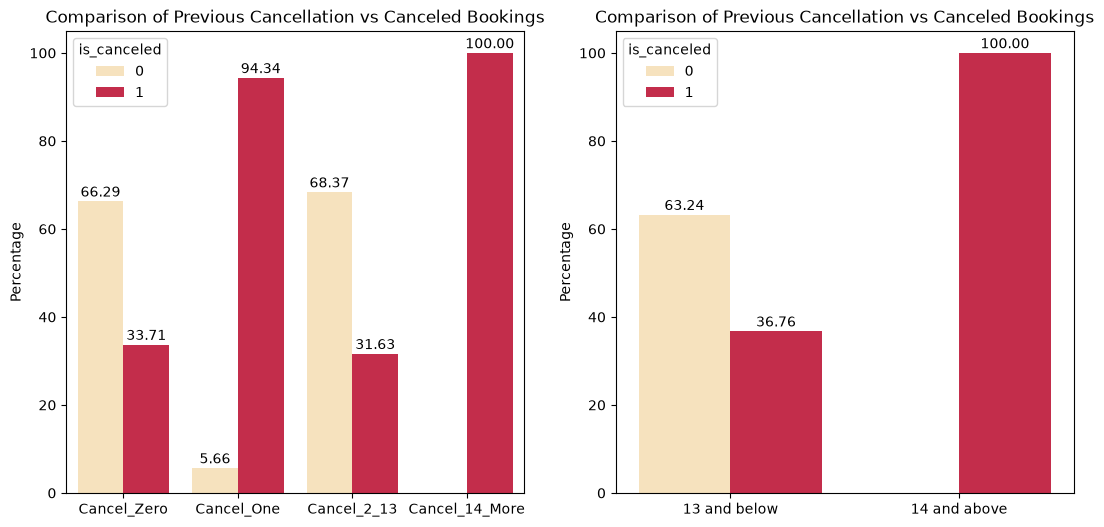

In [14]:
# Binned Cancellations (Specific)
fig, axes = plt.subplots(1, 2, figsize=(13,6))

sns.barplot(data=df_Seg_C, x='Num_Cancel', y='Percentage', hue='is_canceled', palette=Canceled_color, ax=axes[0])
axes[0].set_title('Comparison of Previous Cancellation vs Canceled Bookings')
axes[0].set_xlabel('')
axes[0].set_ylabel('Percentage')

# Bar Annotation
for container in axes[0].containers:
  axes[0].bar_label(container, fmt="%.2f", label_type="edge", color='black', padding=1)

handles, labels = axes[0].get_legend_handles_labels()
new_labels = ['Not Canceled', 'Canceled']

ax.legend(handles=handles, labels=new_labels, title='')

################################################################################################
# Binned Cancellations (2 groups)

df_Req = df[df['previous_cancellations']<=13].groupby(['is_canceled'],as_index=False)['market_segment'].count()
df_Req = df_Req.rename(columns={'market_segment':'Percentage'})

df_Req['Percentage'] =  round ( df_Req['Percentage'] / len(df[df['previous_cancellations']<=13]) * 100 , 2)
df_Req['Num_Cancel'] = '13 and below'

df_NA = df[df['previous_cancellations']>=14].groupby(['is_canceled'],as_index=False)['market_segment'].count()
df_NA = df_NA.rename(columns={'market_segment':'Percentage'})

df_NA['Percentage'] =  round ( df_NA['Percentage'] / len(df[df['previous_cancellations']>=14]) * 100 , 2)
df_NA['Num_Cancel'] = '14 and above'

df_Seg = pd.concat( [df_Req, df_NA], axis=0 )

################################################

sns.barplot(data=df_Seg, x='Num_Cancel', y='Percentage', hue='is_canceled', palette=Canceled_color, ax=axes[1])
axes[1].set_title('Comparison of Previous Cancellation vs Canceled Bookings')
axes[1].set_xlabel('')
axes[1].set_ylabel('Percentage')

# Bar Annotation
for container in axes[1].containers:
  axes[1].bar_label(container, fmt="%.2f", label_type="edge", color='black', padding=1)

handles, labels = axes[1].get_legend_handles_labels()
new_labels = ['Not Canceled', 'Canceled']

ax.legend(handles=handles, labels=new_labels, title='')

Cancellations is better if binned into 4 categories, which provide better differentiation. 

In [15]:
df['previous_cancel'] = np.where( df['previous_cancellations']==0, 'Cancel_0', ' ' )
df['previous_cancel'] = np.where( df['previous_cancellations']==1, 'Cancel_1', df['previous_cancel'] )
df['previous_cancel'] = np.where( (df['previous_cancellations']>=2) & (df['previous_cancellations']<=13), 'Cancel_2_13', df['previous_cancel'] )
df['previous_cancel'] = np.where( df['previous_cancellations']>=14, 'Cancel_14', df['previous_cancel'] )

In [16]:
df.groupby('previous_cancel')['is_canceled'].value_counts()

previous_cancel  is_canceled
Cancel_0         0              52410
                 1              26650
Cancel_1         1               3969
                 0                238
Cancel_14        1                 91
Cancel_2_13      0                147
                 1                 68
Name: count, dtype: int64

##### Booking Changes

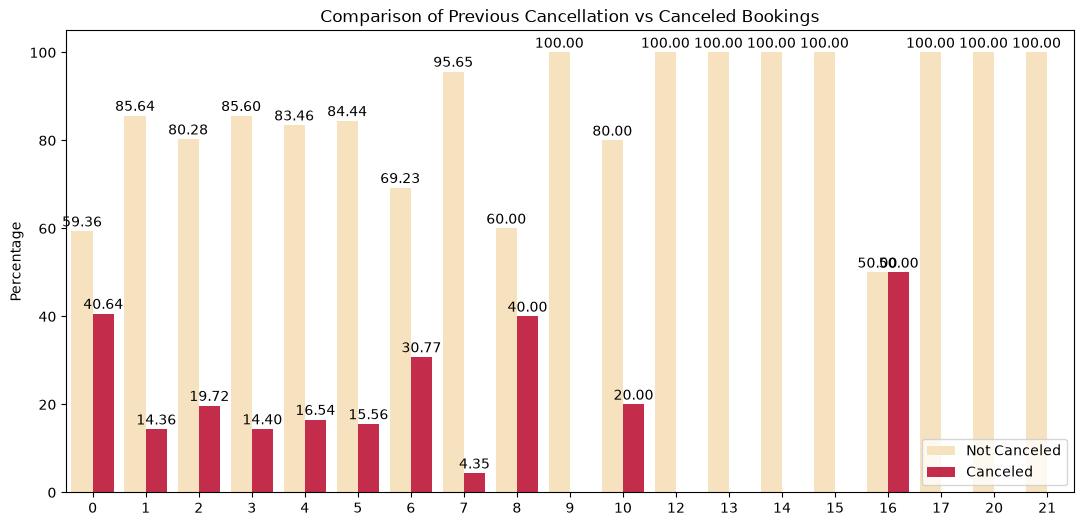

In [17]:
# Booking Changes vs Canceled Bookings

df_Seg = df.groupby(['booking_changes', 'is_canceled'],as_index=False)['customer_type'].count()
df_Seg = df_Seg.rename(columns={'customer_type':'Count'})

df_Sub = df.groupby('booking_changes',as_index=False)[['customer_type']].count()
df_Sub = df_Sub.rename(columns={'customer_type':'Total'})

df_Seg = df_Seg.merge(right=df_Sub[['booking_changes', 'Total']], how='outer')

df_Seg['Percentage'] = round ( df_Seg['Count'] / df_Seg['Total'] * 100 , 2)
df_Seg = df_Seg.sort_values(by=['Total'],ascending=[False]).reset_index(drop=True)

################################################

plt.figure(figsize=(13,6))
ax = sns.barplot(data=df_Seg, x='booking_changes', y='Percentage', hue='is_canceled', palette=Canceled_color)
ax.set_title('Comparison of Previous Cancellation vs Canceled Bookings')
ax.set_xlabel('')
ax.set_ylabel('Percentage')

# Bar Annotation
for container in ax.containers:
  ax.bar_label(container, fmt="%.2f", label_type="edge", color='black', padding=1)

handles, labels = ax.get_legend_handles_labels()
new_labels = ['Not Canceled', 'Canceled']

ax.legend(handles=handles, labels=new_labels, title='', loc='lower right')


In [18]:
df[ df['booking_changes'].isin([8,10,16]) ]['is_canceled'].value_counts()

is_canceled
0    11
1     6
Name: count, dtype: int64

Compared to the total records, guests who made more than 8, 10, 16 booking changes **and** canceled their bookings are rare, consider the total records of 83k.\
"8, 10, 16 booking changes" is selected because the percentage is in rounded number.

In [19]:
# Binned Booking Changes

df_0 = df[df['booking_changes']==0].groupby(['is_canceled'],as_index=False)['market_segment'].count()
df_0 = df_0.rename(columns={'market_segment':'Count'})
df_0['Percentage'] =  round ( df_0['Count'] / len(df[df['previous_cancellations']==0]) * 100 , 2)
df_0['Num_Change'] = 'Change_Zero'

df_1 = df[(df['booking_changes']>=1) & (df['booking_changes']<=7)].groupby(['is_canceled'],as_index=False)['market_segment'].count()
df_1 = df_1.rename(columns={'market_segment':'Count'})
df_1['Percentage'] =  round ( df_1['Count'] / len(df[(df['booking_changes']>=1) & (df['booking_changes']<=7)]) * 100 , 2)
df_1['Num_Change'] = 'Change_1_7'

df_2 = df[df['booking_changes']>=8].groupby(['is_canceled'],as_index=False)['market_segment'].count()
df_2 = df_2.rename(columns={'market_segment':'Count'})
df_2['Percentage'] =  round ( df_2['Count'] / len(df[df['booking_changes']>=8]) * 100 , 2)
df_2['Num_Change'] = 'Change_8_More'

df_Seg_C = pd.concat( [df_0, df_1, df_2], axis=0 ).reset_index(drop=True)
df_Seg_C

,is_canceled,Count,Percentage,Num_Change
0,0,42073,53.22,Change_Zero
1,1,28800,36.43,Change_Zero
2,0,10694,84.43,Change_1_7
3,1,1972,15.57,Change_1_7
4,0,28,82.35,Change_8_More
5,1,6,17.65,Change_8_More


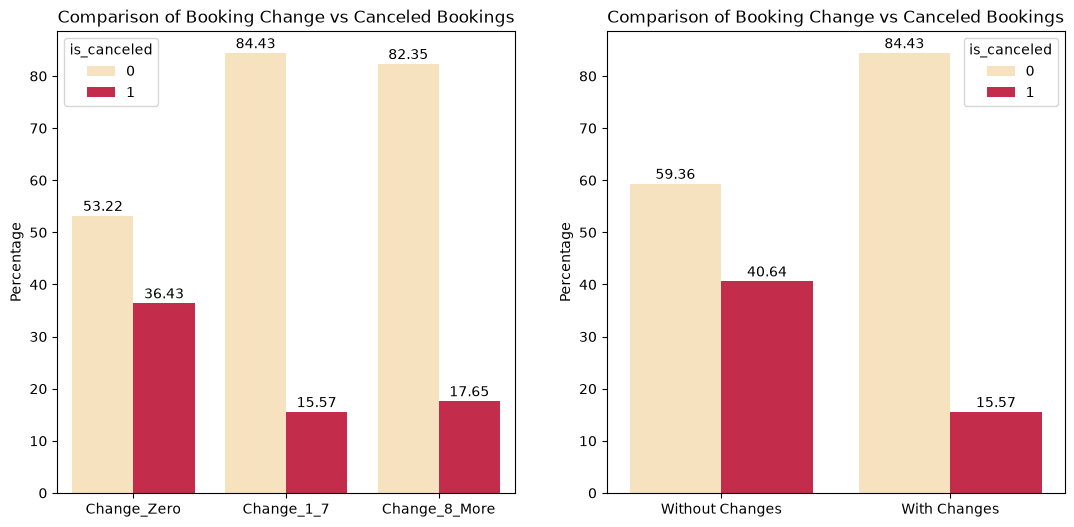

In [20]:
# Binned Changes (Specific)
fig, axes = plt.subplots(1, 2, figsize=(13,6))

sns.barplot(data=df_Seg_C, x='Num_Change', y='Percentage', hue='is_canceled', palette=Canceled_color, ax=axes[0])
axes[0].set_title('Comparison of Booking Change vs Canceled Bookings')
axes[0].set_xlabel('')
axes[0].set_ylabel('Percentage')

# Bar Annotation
for container in axes[0].containers:
  axes[0].bar_label(container, fmt="%.2f", label_type="edge", color='black', padding=1)

handles, labels = axes[0].get_legend_handles_labels()
new_labels = ['Not Canceled', 'Canceled']

ax.legend(handles=handles, labels=new_labels, title='')

################################################################################################
# Binned Cancellations (2 groups)

df_Req = df[df['booking_changes']==0].groupby(['is_canceled'],as_index=False)['market_segment'].count()
df_Req = df_Req.rename(columns={'market_segment':'Percentage'})

df_Req['Percentage'] =  round ( df_Req['Percentage'] / len(df[df['booking_changes']==0]) * 100 , 2)
df_Req['Num_Change'] = 'Without Changes'

df_NA = df[df['booking_changes']!=0].groupby(['is_canceled'],as_index=False)['market_segment'].count()
df_NA = df_NA.rename(columns={'market_segment':'Percentage'})

df_NA['Percentage'] =  round ( df_NA['Percentage'] / len(df[df['booking_changes']!=0]) * 100 , 2)
df_NA['Num_Change'] = 'With Changes'

df_Seg = pd.concat( [df_Req, df_NA], axis=0 )

################################################

sns.barplot(data=df_Seg, x='Num_Change', y='Percentage', hue='is_canceled', palette=Canceled_color, ax=axes[1])
axes[1].set_title('Comparison of Booking Change vs Canceled Bookings')
axes[1].set_xlabel('')
axes[1].set_ylabel('Percentage')

# Bar Annotation
for container in axes[1].containers:
  axes[1].bar_label(container, fmt="%.2f", label_type="edge", color='black', padding=1)

handles, labels = axes[1].get_legend_handles_labels()
new_labels = ['Not Canceled', 'Canceled']

ax.legend(handles=handles, labels=new_labels, title='')

To decide, whether there is difference between using 3 bins, statistic test will be conducted for 'group with booking changes'.

In [21]:
from scipy.stats import chi2_contingency

df_chi2 = pd.concat([df_1, df_2], axis=0)
df_chi2 = df_chi2.pivot_table(values='Count',index='is_canceled', columns='Num_Change')
df_chi2

Num_Change,Change_1_7,Change_8_More
is_canceled,,
0,10694.0,28.0
1,1972.0,6.0


In [22]:
print(chi2_contingency(df_chi2)[1])

0.922822288489936


p-Value: 0.92 | Fail to reject null hypothesis (No significant difference in both groups)\
This feature will be simplified. (With and Without Changes)

In [23]:
# Add column 'is_booking_changes'

df['is_booking_changes'] = np.where( df['booking_changes']==0, 0, 1)

##### Required Parking Space

In [24]:
df[df['total_of_special_requests']==0][['required_car_parking_spaces']].value_counts()

required_car_parking_spaces
0                              46973
1                               2208
2                                  6
8                                  1
Name: count, dtype: int64

Initial assumption: if there is no special request, then there will be no requirement for parking space.\
Based on the dataset, this means 'required_car_parking_spaces' is not part of special request.

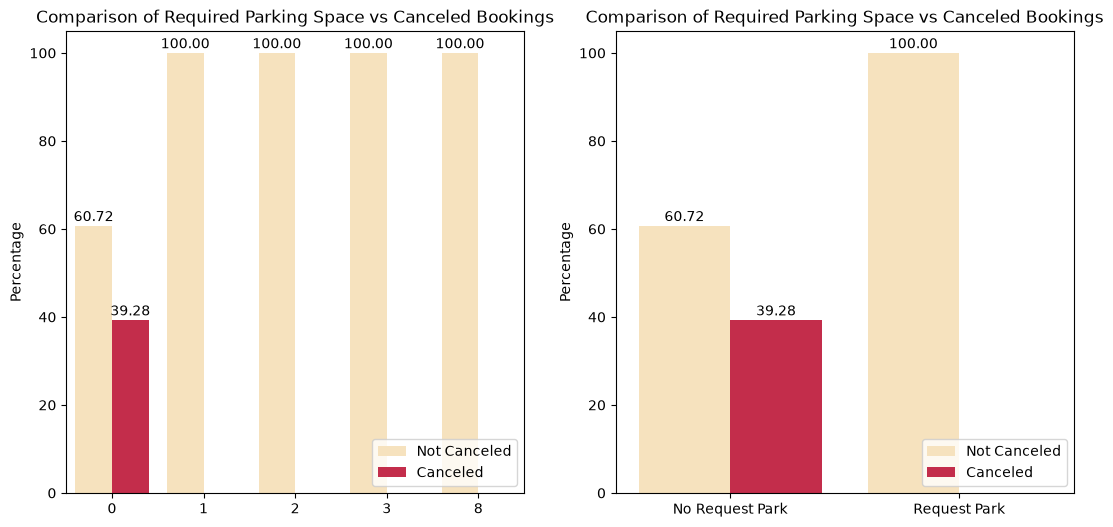

In [25]:
# Parking Space vs Canceled Bookings

df_Seg = df.groupby(['required_car_parking_spaces', 'is_canceled'],as_index=False)['customer_type'].count()
df_Seg = df_Seg.rename(columns={'customer_type':'Count'})

df_Sub = df.groupby('required_car_parking_spaces',as_index=False)[['customer_type']].count()
df_Sub = df_Sub.rename(columns={'customer_type':'Total'})

df_Seg = df_Seg.merge(right=df_Sub[['required_car_parking_spaces', 'Total']], how='outer')

df_Seg['Percentage'] = round ( df_Seg['Count'] / df_Seg['Total'] * 100 , 2)
df_Seg = df_Seg.sort_values(by=['Total'],ascending=[False]).reset_index(drop=True)

################################################

fig, axes = plt.subplots(1, 2, figsize=(13,6))
sns.barplot(data=df_Seg, x='required_car_parking_spaces', y='Percentage', hue='is_canceled', palette=Canceled_color, ax=axes[0])
axes[0].set_title('Comparison of Required Parking Space vs Canceled Bookings')
axes[0].set_xlabel('')
axes[0].set_ylabel('Percentage')

# Bar Annotation
for container in axes[0].containers:
  axes[0].bar_label(container, fmt="%.2f", label_type="edge", color='black', padding=1)

handles, labels = axes[0].get_legend_handles_labels()
new_labels = ['Not Canceled', 'Canceled']

axes[0].legend(handles=handles, labels=new_labels, title='', loc='lower right')

################################################################################################

df_Req = df[df['required_car_parking_spaces']==0].groupby(['is_canceled'],as_index=False)['market_segment'].count()
df_Req = df_Req.rename(columns={'market_segment':'Percentage'})

df_Req['Percentage'] =  round ( df_Req['Percentage'] / len(df[df['required_car_parking_spaces']==0]) * 100 , 2)
df_Req['Req_Park'] = 'No Request Park'

df_NA = df[df['required_car_parking_spaces']!=0].groupby(['is_canceled'],as_index=False)['market_segment'].count()
df_NA = df_NA.rename(columns={'market_segment':'Percentage'})

df_NA['Percentage'] =  round ( df_NA['Percentage'] / len(df[df['required_car_parking_spaces']!=0]) * 100 , 2)
df_NA['Req_Park'] = 'Request Park'

df_Seg = pd.concat( [df_Req, df_NA], axis=0 )

################################################

sns.barplot(data=df_Seg, x='Req_Park', y='Percentage', hue='is_canceled', palette=Canceled_color, ax=axes[1])
axes[1].set_title('Comparison of Required Parking Space vs Canceled Bookings')
axes[1].set_xlabel('')
axes[1].set_ylabel('Percentage')

# Bar Annotation
for container in axes[1].containers:
  axes[1].bar_label(container, fmt="%.2f", label_type="edge", color='black', padding=1)

handles, labels = axes[1].get_legend_handles_labels()
new_labels = ['Not Canceled', 'Canceled']

axes[1].legend(handles=handles, labels=new_labels, title='', loc='lower right')

Based on dataset, guests who made requests of parking spaces (at least 1), do not cancel their bookings.\
This feature will be simplified.

In [26]:
# Add column 'is_req_parking'

df['is_req_parking'] = np.where( df['required_car_parking_spaces']==0, 0, 1)

##### Days in waiting list

Text(0, 0.5, '')

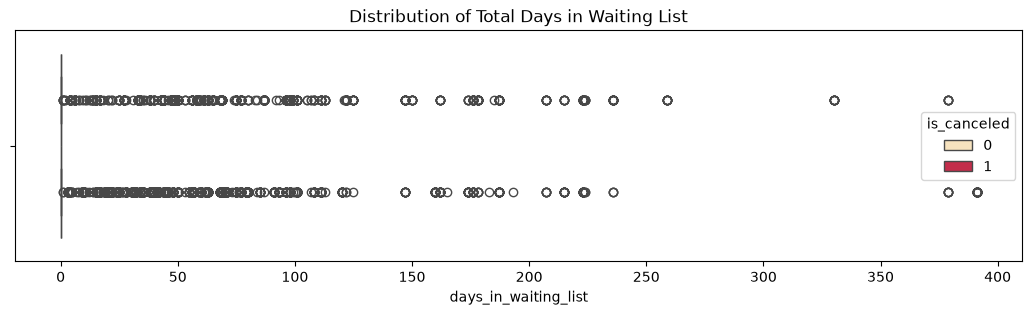

In [27]:
# Distribution of days_in_waiting_list

plt.figure(figsize=(13,3))

ax = sns.boxplot(data=df, x='days_in_waiting_list', hue='is_canceled', palette=Canceled_color)
ax.set_title('Distribution of Total Days in Waiting List')
ax.set_ylabel('')

In [28]:
# Add column months_waiting_list

# Day 1 - 30 >> Month 1 ; Day 31 - 60 >> Month 2
df['months_waiting_list'] = df['days_in_waiting_list'].apply(lambda x: math.ceil(x/30))


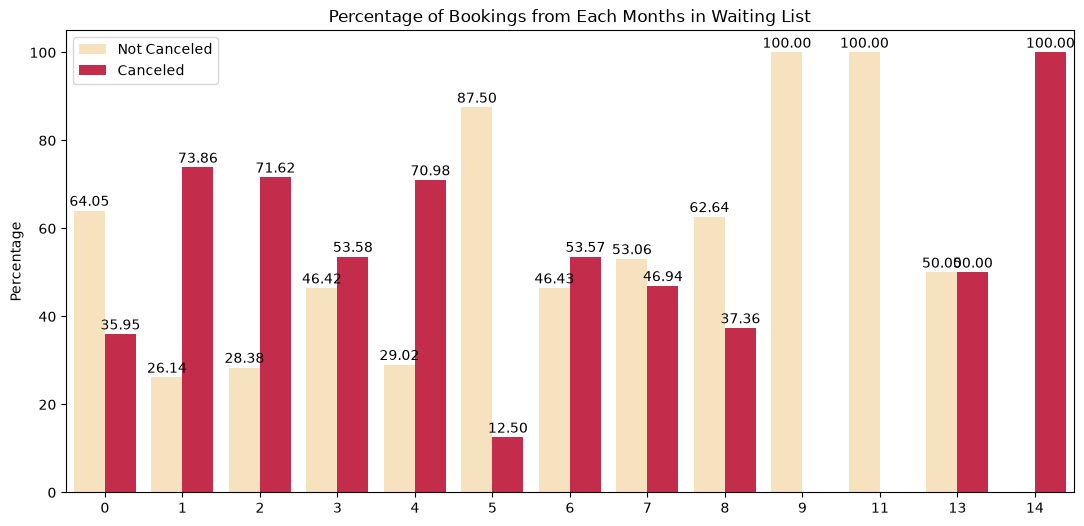

In [29]:
# Months in Waiting List vs Canceled Bookings

df_Seg = df.groupby(['months_waiting_list', 'is_canceled'],as_index=False)['customer_type'].count()
df_Seg = df_Seg.rename(columns={'customer_type':'Count'})

df_Sub = df.groupby('months_waiting_list',as_index=False)[['customer_type']].count()
df_Sub = df_Sub.rename(columns={'customer_type':'Total'})

df_Seg = df_Seg.merge(right=df_Sub[['months_waiting_list', 'Total']], how='outer')

df_Seg['Percentage'] = round ( df_Seg['Count'] / df_Seg['Total'] * 100 , 2)
df_Seg = df_Seg.sort_values(by=['Total'],ascending=[False]).reset_index(drop=True)

################################################

plt.figure(figsize=(13,6))
ax = sns.barplot(data=df_Seg, x='months_waiting_list', y='Percentage', hue='is_canceled', palette=Canceled_color)
ax.set_title('Percentage of Bookings from Each Months in Waiting List')
ax.set_xlabel('')
ax.set_ylabel('Percentage')

# Bar Annotation
for container in ax.containers:
  ax.bar_label(container, fmt="%.2f", label_type="edge", color='black', padding=1)

handles, labels = ax.get_legend_handles_labels()
new_labels = ['Not Canceled', 'Canceled']

ax.legend(handles=handles, labels=new_labels, title='')

In [30]:
print ( df[df['months_waiting_list']>12]['is_canceled'].value_counts() )

print ( df[df['months_waiting_list']>12]['is_canceled'].value_counts() / len(df[df['months_waiting_list']>12]) )

is_canceled
1    38
0     5
Name: count, dtype: int64
is_canceled
1    0.883721
0    0.116279
Name: count, dtype: float64


In [31]:
# Only little records with bookings made > 1 year; categorized as one 

idx = df[df['months_waiting_list']>12].index

df.loc[idx, 'months_waiting_list' ] = 13

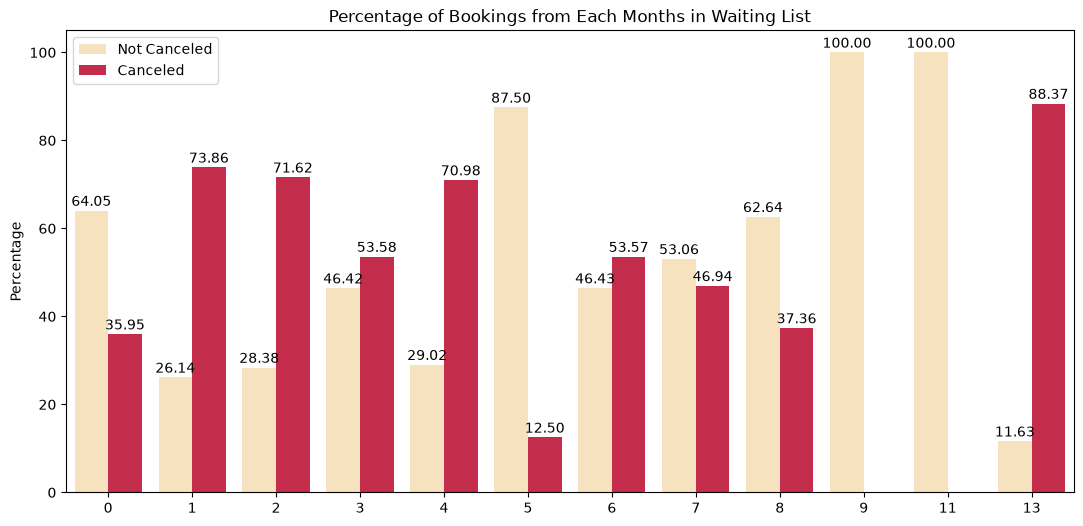

In [32]:
# Months is Waiting List vs Canceled Bookings

df_Seg = df.groupby(['months_waiting_list', 'is_canceled'],as_index=False)['customer_type'].count()
df_Seg = df_Seg.rename(columns={'customer_type':'Count'})

df_Sub = df.groupby('months_waiting_list',as_index=False)[['customer_type']].count()
df_Sub = df_Sub.rename(columns={'customer_type':'Total'})

df_Seg = df_Seg.merge(right=df_Sub[['months_waiting_list', 'Total']], how='outer')

df_Seg['Percentage'] = round ( df_Seg['Count'] / df_Seg['Total'] * 100 , 2)
df_Seg = df_Seg.sort_values(by=['Total'],ascending=[False]).reset_index(drop=True)

################################################

plt.figure(figsize=(13,6))
ax = sns.barplot(data=df_Seg, x='months_waiting_list', y='Percentage', hue='is_canceled', palette=Canceled_color)
ax.set_title('Percentage of Bookings from Each Months in Waiting List')
ax.set_xlabel('')
ax.set_ylabel('Percentage')

# Bar Annotation
for container in ax.containers:
  ax.bar_label(container, fmt="%.2f", label_type="edge", color='black', padding=1)

handles, labels = ax.get_legend_handles_labels()
new_labels = ['Not Canceled', 'Canceled']

ax.legend(handles=handles, labels=new_labels, title='')

##### Total Special Requests

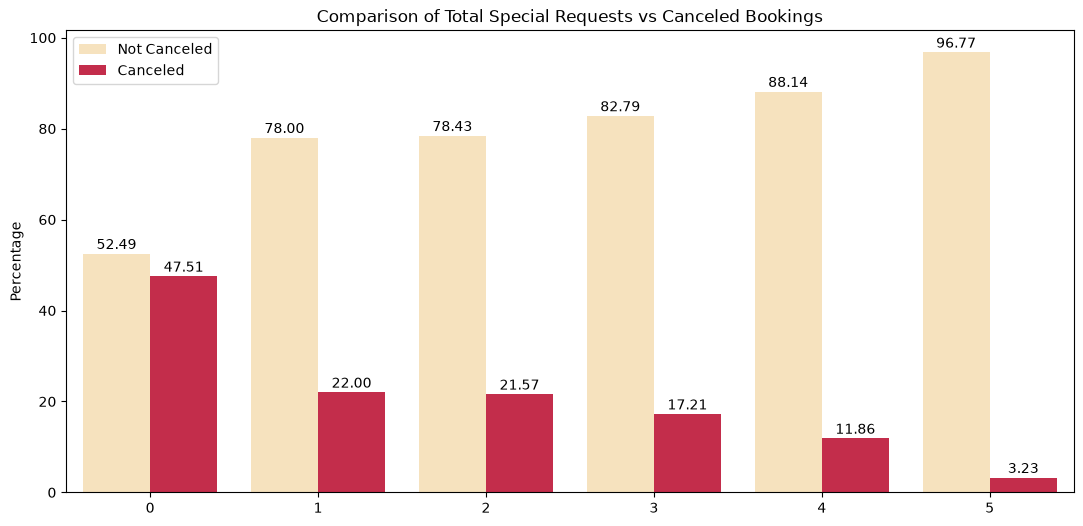

In [33]:
# Total Special Requests vs Canceled Bookings

df_Seg = df.groupby(['total_of_special_requests', 'is_canceled'],as_index=False)['customer_type'].count()
df_Seg = df_Seg.rename(columns={'customer_type':'Count'})

df_Sub = df.groupby('total_of_special_requests',as_index=False)[['customer_type']].count()
df_Sub = df_Sub.rename(columns={'customer_type':'Total'})

df_Seg = df_Seg.merge(right=df_Sub[['total_of_special_requests', 'Total']], how='outer')

df_Seg['Percentage'] = round ( df_Seg['Count'] / df_Seg['Total'] * 100 , 2)
df_Seg = df_Seg.sort_values(by=['Total'],ascending=[False]).reset_index(drop=True)

################################################

plt.figure(figsize=(13,6))
ax = sns.barplot(data=df_Seg, x='total_of_special_requests', y='Percentage', hue='is_canceled', palette=Canceled_color)
ax.set_title('Comparison of Total Special Requests vs Canceled Bookings')
ax.set_xlabel('')
ax.set_ylabel('Percentage')

# Bar Annotation
for container in ax.containers:
  ax.bar_label(container, fmt="%.2f", label_type="edge", color='black', padding=1)

handles, labels = ax.get_legend_handles_labels()
new_labels = ['Not Canceled', 'Canceled']

ax.legend(handles=handles, labels=new_labels, title='')


Conduct Chi-Squared test to know, whether there are different proportions for guests with special requests.

In [34]:
ChiSq = {
    'Group' : [],
    'p-Val' : []
}

req_uniq = df_Seg['total_of_special_requests'].unique()

for x in range(1, len(req_uniq)):
    for y in range(2, len(req_uniq)):
        if x >= y: 
            pass
        else:
            df_chi2 = df_Seg[ (df_Seg['total_of_special_requests']>=x) & (df_Seg['total_of_special_requests']<= y) ]
            df_chi2 = df_chi2.pivot_table(values='Count',index='total_of_special_requests', columns='is_canceled')
            ChiSq['Group'].append(f'Special Request: {x} - {y}')
            ChiSq['p-Val'].append( chi2_contingency(df_chi2)[1] )
        
df_Chi_Result = pd.DataFrame(ChiSq)
df_Chi_Result

,Group,p-Val
0,Special Request: 1 - 2,4.113224e-01
1,Special Request: 1 - 3,1.352308e-05
2,Special Request: 1 - 4,8.707322e-08
3,Special Request: 1 - 5,1.773825e-08
4,Special Request: 2 - 3,3.903867e-05
5,Special Request: 2 - 4,5.900528e-07
6,Special Request: 2 - 5,1.568675e-07
7,Special Request: 3 - 4,4.756476e-02
8,Special Request: 3 - 5,1.558663e-02
9,Special Request: 4 - 5,2.516730e-01


All special requests have different proportions. This column will not be changed.

##### Market Segment

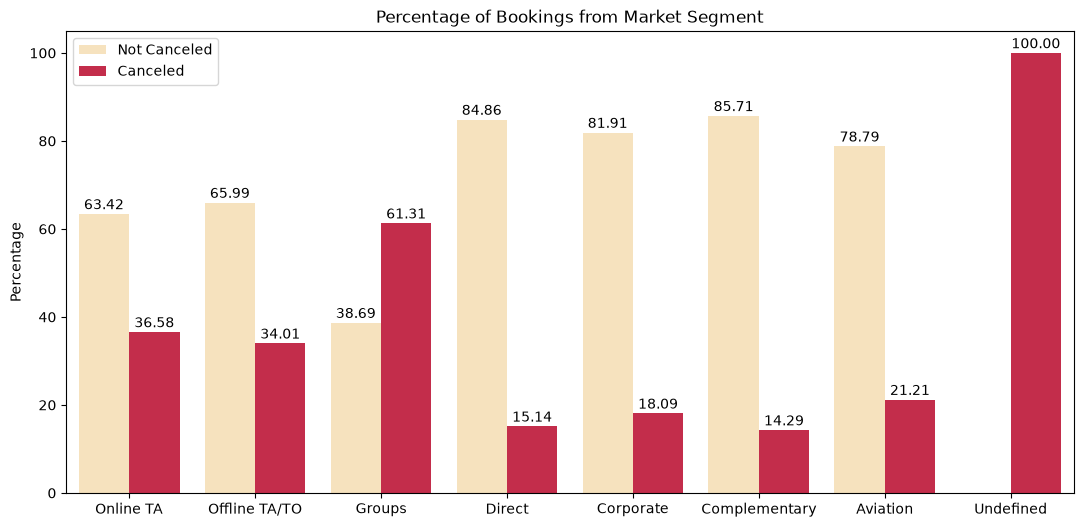

In [35]:
# Market Segment vs Canceled Bookings

df_Seg = df.groupby(['market_segment', 'is_canceled'],as_index=False)['customer_type'].count()
df_Seg = df_Seg.rename(columns={'customer_type':'Count'})

df_Sub = df.groupby('market_segment',as_index=False)[['customer_type']].count()
df_Sub = df_Sub.rename(columns={'customer_type':'Total'})

df_Seg = df_Seg.merge(right=df_Sub[['market_segment', 'Total']], how='outer')

df_Seg['Percentage'] = round ( df_Seg['Count'] / df_Seg['Total'] * 100 , 2)
df_Seg = df_Seg.sort_values(by=['Total'],ascending=[False]).reset_index(drop=True)

################################################

plt.figure(figsize=(13,6))
ax = sns.barplot(data=df_Seg, x='market_segment', y='Percentage', hue='is_canceled', palette=Canceled_color)
ax.set_title('Percentage of Bookings from Market Segment')
ax.set_xlabel('')
ax.set_ylabel('Percentage')

# Bar Annotation
for container in ax.containers:
  ax.bar_label(container, fmt="%.2f", label_type="edge", color='black', padding=1)

handles, labels = ax.get_legend_handles_labels()
new_labels = ['Not Canceled', 'Canceled']

ax.legend(handles=handles, labels=new_labels, title='')

In [36]:
# Undefined market segment
df[df['market_segment']=='Undefined']

,country,market_segment,previous_cancellations,booking_changes,deposit_type,days_in_waiting_list,customer_type,reserved_room_type,required_car_parking_spaces,total_of_special_requests,is_canceled,previous_cancel,is_booking_changes,is_req_parking,months_waiting_list
70217,PRT,Undefined,0,0,No Deposit,0,Transient-Party,B,0,1,1,Cancel_0,0,0,0


In [37]:
# Drop the record

df = df.drop( index= df[df['market_segment']=='Undefined'].index[0] ).reset_index(drop=True)
print ( df[df['is_canceled']==1]['market_segment'].value_counts().index )


Index(['Online TA', 'Groups', 'Offline TA/TO', 'Direct', 'Corporate',
       'Complementary', 'Aviation'],
      dtype='str', name='market_segment')


##### Customer Type

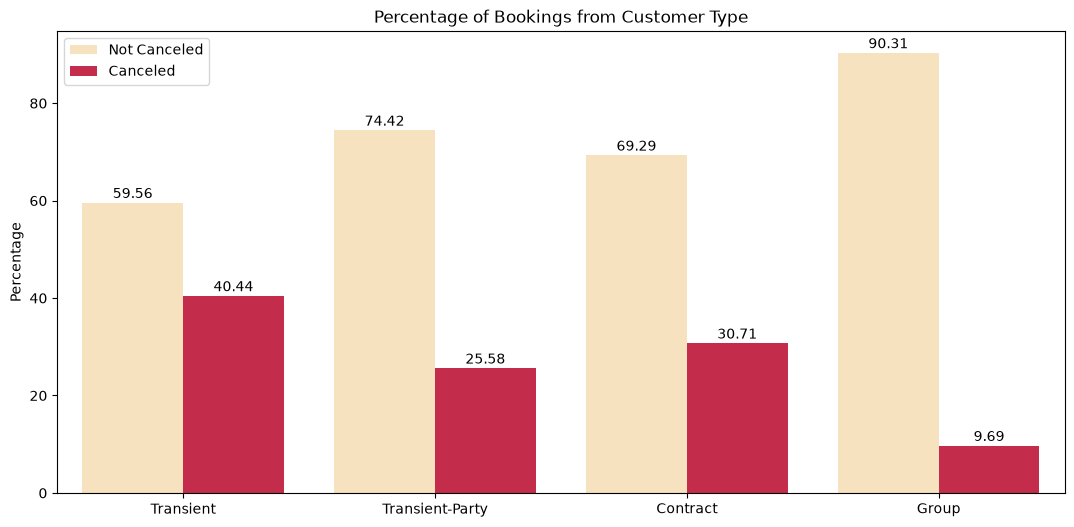

In [38]:
# Customer Type vs Canceled Bookings

df_Seg = df.groupby(['customer_type', 'is_canceled'],as_index=False)['market_segment'].count()
df_Seg = df_Seg.rename(columns={'market_segment':'Count'})

df_Sub = df.groupby('customer_type',as_index=False)[['market_segment']].count()
df_Sub = df_Sub.rename(columns={'market_segment':'Total'})

df_Seg = df_Seg.merge(right=df_Sub[['customer_type', 'Total']], how='outer')

df_Seg['Percentage'] = round ( df_Seg['Count'] / df_Seg['Total'] * 100 , 2)
df_Seg = df_Seg.sort_values(by=['Total'],ascending=[False]).reset_index(drop=True)

################################################

plt.figure(figsize=(13,6))
ax = sns.barplot(data=df_Seg, x='customer_type', y='Percentage', hue='is_canceled', palette=Canceled_color)
ax.set_title('Percentage of Bookings from Customer Type')
ax.set_xlabel('')
ax.set_ylabel('Percentage')

# Bar Annotation
for container in ax.containers:
  ax.bar_label(container, fmt="%.2f", label_type="edge", color='black', padding=1)

handles, labels = ax.get_legend_handles_labels()
new_labels = ['Not Canceled', 'Canceled']

ax.legend(handles=handles, labels=new_labels, title='')

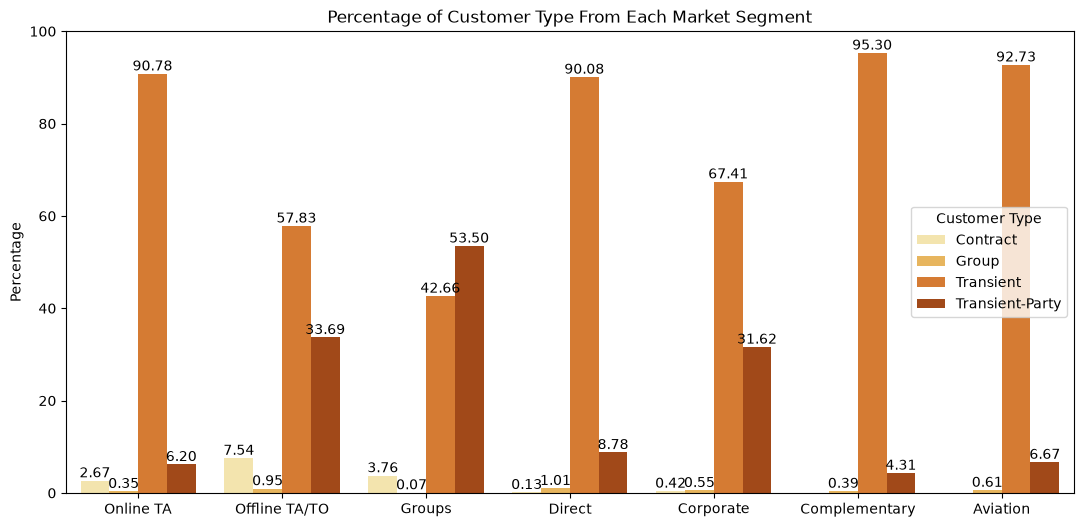

In [39]:
# Customer Type From Each Market Segment

df_Seg = df.groupby(['market_segment', 'customer_type'],as_index=False)['is_canceled'].count()
df_Seg = df_Seg.rename(columns={'is_canceled':'Count'})

df_Sub = df.groupby('market_segment',as_index=False)[['is_canceled']].count()
df_Sub = df_Sub.rename(columns={'is_canceled':'Total'})

df_Seg = df_Seg.merge(right=df_Sub[['market_segment', 'Total']], how='outer')

df_Seg['Percentage'] = round ( df_Seg['Count'] / df_Seg['Total'] * 100 , 2)
df_Seg = df_Seg.sort_values(by=['Total','customer_type'],ascending=[False,True])

################################################

plt.figure(figsize=(13,6))
ax = sns.barplot(data=df_Seg, x='market_segment', y='Percentage', hue='customer_type', palette='YlOrBr')
ax.set_title('Percentage of Customer Type From Each Market Segment')
ax.set_xlabel('')
ax.set_ylabel('Percentage')

# Bar Annotation
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", label_type='edge', color='black', fontsize=10 )

ax.legend(title='Customer Type')

Most market segments are from Transient Customer Type

##### Deposit Type

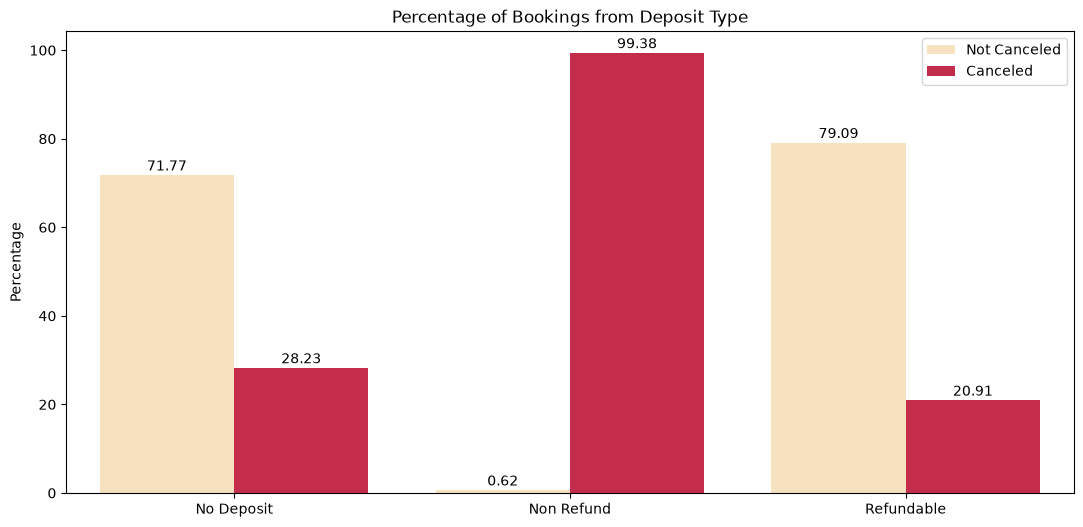

In [40]:
# Deposit Type vs Canceled Bookings

df_Seg = df.groupby(['deposit_type', 'is_canceled'],as_index=False)['market_segment'].count()
df_Seg = df_Seg.rename(columns={'market_segment':'Count'})

df_Sub = df.groupby('deposit_type',as_index=False)[['market_segment']].count()
df_Sub = df_Sub.rename(columns={'market_segment':'Total'})

df_Seg = df_Seg.merge(right=df_Sub[['deposit_type', 'Total']], how='outer')

df_Seg['Percentage'] = round ( df_Seg['Count'] / df_Seg['Total'] * 100 , 2)
df_Seg = df_Seg.sort_values(by=['Total'],ascending=[False]).reset_index(drop=True)

################################################

plt.figure(figsize=(13,6))
ax = sns.barplot(data=df_Seg, x='deposit_type', y='Percentage', hue='is_canceled', palette=Canceled_color)
ax.set_title('Percentage of Bookings from Deposit Type')
ax.set_xlabel('')
ax.set_ylabel('Percentage')

# Bar Annotation
for container in ax.containers:
  ax.bar_label(container, fmt="%.2f", label_type="edge", color='black', padding=1)

handles, labels = ax.get_legend_handles_labels()
new_labels = ['Not Canceled', 'Canceled']

ax.legend(handles=handles, labels=new_labels, title='')

Interestingly, guests who made Non Refund Deposit, have the highest cancel percentage rate.

##### Country

In [41]:
df['country'].mode()

0    PRT
Name: country, dtype: str

In [42]:
# PRT is the ISO 3166-1 alpha-3 country code for Portugal. (Which means domestic hotel guests)
# It is suitable to fill missing values with PRT

df['country'] = df['country'].fillna(value='PRT')

In [43]:
# Add column continent, to reduce granularity in 'country'

# pip install country_converter
import country_converter as coco

cc = coco.CountryConverter()

# Exclude Nan Values
not_nan_idx = df['country'].notna()

df['continent'] = None
df.loc[not_nan_idx, 'continent' ] = cc.convert(names= df.loc[not_nan_idx, 'country' ] , to='continent')


TMP not found in ISO3
TMP not found in ISO3


In [44]:
# The TMP country code is the former ISO 3166-1 alpha-3 code for East Timor (Replaced by TLS)
idx = df[df['country']=='TMP'].index
df.loc [ idx , 'country'] = 'TSL'
df.loc [ idx , 'continent'] = 'Asia'

In [45]:
df['continent'].unique()

array(['Europe', 'Oceania', 'Asia', 'America', 'Africa', 'Antarctica'],
      dtype=object)

In [46]:
# ATA is the three-letter country code (alpha-3) for Antarctica
# Antarctica does not have its own government, border control, or official entry visa

df[df['continent']=='Antarctica']

,country,market_segment,previous_cancellations,booking_changes,deposit_type,days_in_waiting_list,customer_type,reserved_room_type,required_car_parking_spaces,total_of_special_requests,is_canceled,previous_cancel,is_booking_changes,is_req_parking,months_waiting_list,continent
2054,ATA,Direct,0,0,No Deposit,0,Transient,E,0,0,0,Cancel_0,0,0,0,Antarctica


In [47]:
df = df.drop(index=df[df['continent']=='Antarctica'].index).reset_index(drop=True)

In [48]:
df['continent'].unique()

array(['Europe', 'Oceania', 'Asia', 'America', 'Africa'], dtype=object)

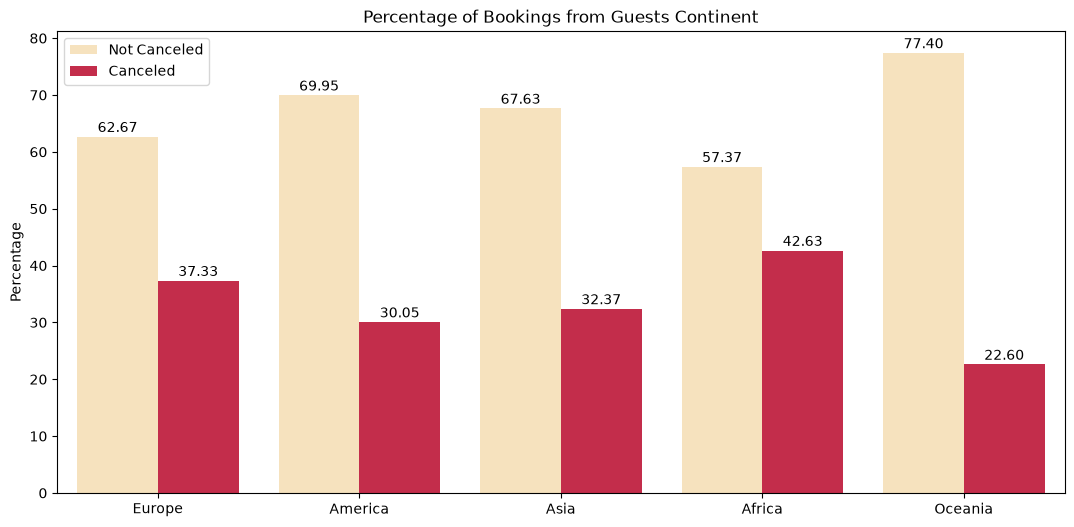

In [49]:
# Continent vs Canceled Bookings

df_Seg = df.groupby(['continent', 'is_canceled'],as_index=False)['market_segment'].count()
df_Seg = df_Seg.rename(columns={'market_segment':'Count'})

df_Sub = df.groupby('continent',as_index=False)[['market_segment']].count()
df_Sub = df_Sub.rename(columns={'market_segment':'Total'})

df_Seg = df_Seg.merge(right=df_Sub[['continent', 'Total']], how='outer')

df_Seg['Percentage'] = round ( df_Seg['Count'] / df_Seg['Total'] * 100 , 2)
df_Seg = df_Seg.sort_values(by=['Total'],ascending=[False]).reset_index(drop=True)

################################################

plt.figure(figsize=(13,6))
ax = sns.barplot(data=df_Seg, x='continent', y='Percentage', hue='is_canceled', palette=Canceled_color)
ax.set_title('Percentage of Bookings from Guests Continent')
ax.set_xlabel('')
ax.set_ylabel('Percentage')

# Bar Annotation
for container in ax.containers:
  ax.bar_label(container, fmt="%.2f", label_type="edge", color='black', padding=1)

handles, labels = ax.get_legend_handles_labels()
new_labels = ['Not Canceled', 'Canceled']

ax.legend(handles=handles, labels=new_labels, title='')

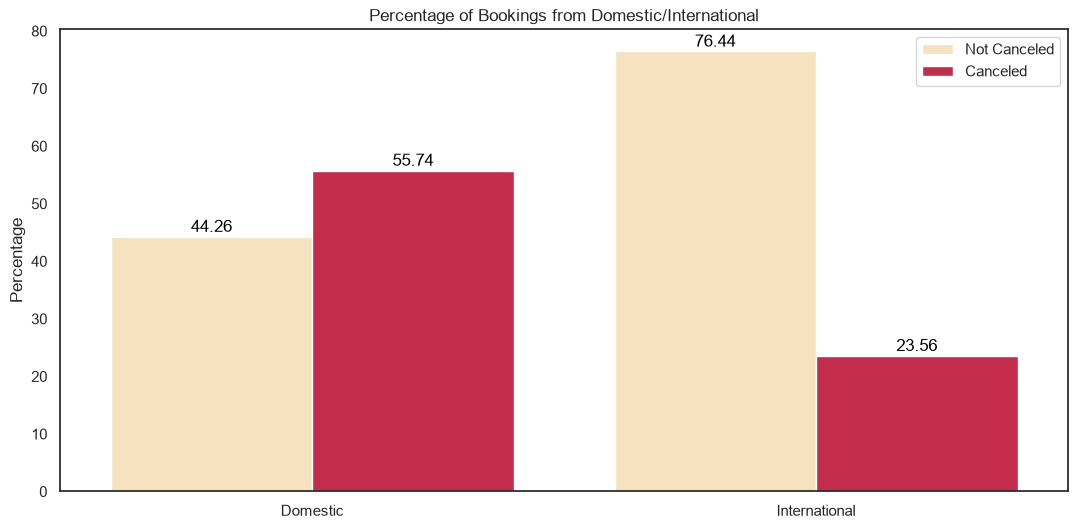

In [50]:
# Domestic and International vs Canceled Bookings
# PRT is the ISO 3166-1 alpha-3 country code for Portugal.

df_Domestic = df[df['country']=='PRT'].groupby(['is_canceled'],as_index=False)['market_segment'].count()
df_Domestic = df_Domestic.rename(columns={'market_segment':'Percentage'})

df_Domestic['Percentage'] =  round ( df_Domestic['Percentage'] / len(df[df['country']=='PRT']) * 100 , 2)
df_Domestic['Country'] = 'Domestic'

df_Intl = df[df['country']!='PRT'].groupby(['is_canceled'],as_index=False)['market_segment'].count()
df_Intl = df_Intl.rename(columns={'market_segment':'Percentage'})

df_Intl['Percentage'] =  round ( df_Intl['Percentage'] / len(df[df['country']!='PRT']) * 100 , 2)
df_Intl['Country'] = 'International'

df_Guests = pd.concat( [df_Domestic, df_Intl], axis=0 )

################################################

plt.figure(figsize=(13,6))
sns.set_theme(style='white')
ax = sns.barplot(data=df_Guests, x='Country', y='Percentage', hue='is_canceled', palette=Canceled_color)
ax.set_title('Percentage of Bookings from Domestic/International')
ax.set_xlabel('')
ax.set_ylabel('Percentage')

# Bar Annotation
for container in ax.containers:
  ax.bar_label(container, fmt="%.2f", label_type="edge", color='black', padding=1)

handles, labels = ax.get_legend_handles_labels()
new_labels = ['Not Canceled', 'Canceled']

ax.legend(handles=handles, labels=new_labels, title='')

Add 'Domestic' column to differentiate better.

In [51]:
# Add column 'is_domestic'

df['is_domestic'] = np.where( df['country']=='PRT', 1, 0)

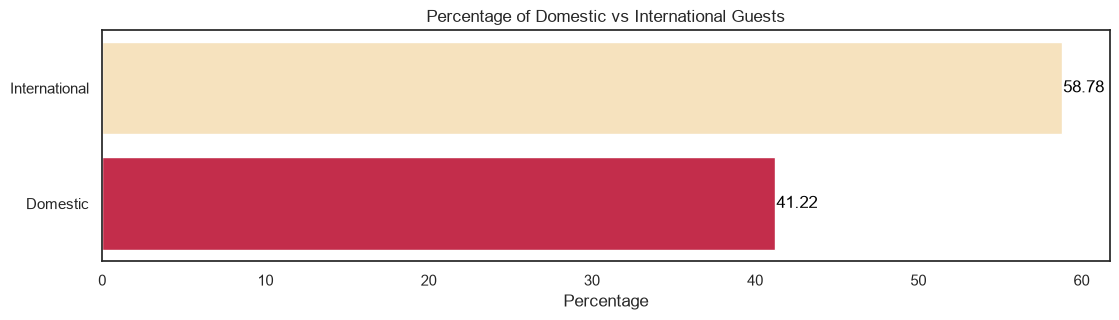

In [52]:
# Percentage of Domestic vs International Guests

plt.figure(figsize=(13,3))
ax = sns.countplot(data=df, y='is_domestic', stat='percent', hue='is_domestic', palette=Canceled_color, legend=False)
ax.set_title('Percentage of Domestic vs International Guests')
ax.set_ylabel('')
ax.set_xlabel('Percentage')
plt.yticks(ticks=[0,1], labels=['International', 'Domestic'])

# Bar Annotation
for container in ax.containers:
  ax.bar_label(container, fmt="%.2f", label_type="edge", color='black', padding=1)


#### Cleaned Dataset

In [53]:
#Unique Values from Dataset
Unique_Dict = {
    'columns' : [],
    'unique_count' : [],
    'unique' : [],
    'dtype' : []
}

for idx in range( len(df.columns) ) :
    Unique_Dict['columns'].append(df.columns[idx])
    Unique_Dict['unique_count'].append(df[df.columns[idx]].nunique())
    if (df[df.columns[idx]].nunique()) < 20:
        Unique_Dict['unique'].append(df[df.columns[idx]].unique())
    else:
        Unique_Dict['unique'].append('More than 20')
    Unique_Dict['dtype'].append(df.dtypes.iloc[idx])

pd.DataFrame(Unique_Dict)

,columns,unique_count,unique,dtype
0,country,161,More than 20,str
1,market_segment,7,"[Offline TA/TO, Online TA, Direct, Groups, Corporate, Complementary, Aviation]",str
2,previous_cancellations,15,"[0, 1, 25, 2, 3, 11, 24, 13, 6, 26, 14, 4, 19, 5, 21]",int64
3,booking_changes,19,"[0, 1, 2, 5, 3, 4, 6, 7, 9, 8, 17, 10, 13, 12, 14, 21, 16, 20, 15]",int64
4,deposit_type,3,"[No Deposit, Non Refund, Refundable]",str
5,days_in_waiting_list,115,More than 20,int64
6,customer_type,4,"[Transient-Party, Transient, Contract, Group]",str
7,reserved_room_type,10,"[A, E, D, F, B, G, C, H, L, P]",str
8,required_car_parking_spaces,5,"[0, 1, 2, 8, 3]",int64
9,total_of_special_requests,6,"[0, 2, 1, 3, 4, 5]",int64


In [54]:
df.isna().sum()

country                        0
market_segment                 0
previous_cancellations         0
booking_changes                0
deposit_type                   0
days_in_waiting_list           0
customer_type                  0
reserved_room_type             0
required_car_parking_spaces    0
total_of_special_requests      0
is_canceled                    0
previous_cancel                0
is_booking_changes             0
is_req_parking                 0
months_waiting_list            0
continent                      0
is_domestic                    0
dtype: int64

In [55]:
df_trf = df.copy().rename(columns={
    'market_segment' : 'market_seg',
    'previous_cancellations' : 'prev_cancel',
    'reserved_room_type' : 'room_type', 
    'required_car_parking_spaces' : 'req_car_spaces',
    'months_waiting_list' : 'months_wait_list',
    'total_of_special_requests' : 'spec_requests'
})

In [56]:
df_trf.to_csv(path + 'df_transformed.csv')

### Data Preprocessing: Feature Engineering

In [57]:
# Import Library

# Data Splitting
from sklearn.model_selection import train_test_split

# Pipeline
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline

# Missing values
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import SimpleImputer, KNNImputer

# Encoding
from sklearn.preprocessing import OneHotEncoder

# Binning
from sklearn.preprocessing import KBinsDiscretizer

# Scaling
from sklearn.preprocessing import MinMaxScaler, StandardScaler, RobustScaler

# Column Transformer
from sklearn.compose import ColumnTransformer

# Imbalanced
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler

# Metrics
from sklearn.metrics import fbeta_score
from sklearn.metrics import make_scorer

# Save Model
import pickle

In [58]:
df_trf = pd.read_csv(path + 'df_transformed.csv')

In [59]:
df_trf.columns

Index(['Unnamed: 0', 'country', 'market_seg', 'prev_cancel', 'booking_changes',
       'deposit_type', 'days_in_waiting_list', 'customer_type', 'room_type',
       'req_car_spaces', 'spec_requests', 'is_canceled', 'previous_cancel',
       'is_booking_changes', 'is_req_parking', 'months_wait_list', 'continent',
       'is_domestic'],
      dtype='str')

In [60]:
# Define feature and target

X = df_trf.drop(columns=['Unnamed: 0', 'is_canceled', 'country', 'prev_cancel', 'booking_changes', 
                         'days_in_waiting_list', 'room_type', 'req_car_spaces'])

# Target; 1 = cancel booking, 0 = non canceled
y = df_trf['is_canceled']

In [61]:
# Training Data, Validation Data, Test Data

# Split with 80% train and 20% test data
X_trainval, X_test, y_trainval, y_test = train_test_split(X, y, test_size=0.2, random_state=13, stratify=y)

# Split train data with 75% train and 25% validation data
X_train, X_val, y_train, y_val = train_test_split(X_trainval, y_trainval, test_size=0.25, random_state=13, stratify=y_trainval)

# 60% train data; 20% validation data; 20% test data

In [62]:
# Define f beta score (beta = 0.5)
f_bscore = make_scorer(fbeta_score, beta = 0.5)

In [63]:
# Define Model Pipeline for Pre-processing data & Column Transform

transformer = ColumnTransformer([
    ('onehot', OneHotEncoder(handle_unknown='error'),
     ['market_seg', 'deposit_type','customer_type', 'previous_cancel', 'spec_requests', 'continent'] ),
    ('scaler_months', MinMaxScaler(), ['months_wait_list'])
], remainder='passthrough') # 'is_booking_changes', 'is_req_parking', 'is_domestic'

transformer

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('onehot', ...), ('scaler_months', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` 

### Modeling

In [64]:
# Import Library

# Cross validation
from sklearn.model_selection import cross_val_score, cross_validate

# Hyperparameter tuning
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

# Base-learner Modeling
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression

# Ensemble various type
from sklearn.ensemble import VotingClassifier, StackingClassifier

# Ensemble similar type
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# Stratified KFold (Classification)
from sklearn.model_selection import StratifiedKFold

# Metrics
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score
from sklearn.metrics import get_scorer_names
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# Measure Runtime
import time
from sklearn.model_selection import ParameterGrid

#### Benchmark Model

In [65]:
# Define Machine Learning Algorithm with Default Parameters

# Base learners
mod_Log = LogisticRegression(class_weight='balanced', max_iter=1000)
mod_KNN = KNeighborsClassifier()
mod_Tree = DecisionTreeClassifier()

# Ensemble various
mod_voting = VotingClassifier(estimators=[('clf1', mod_Log),
                                      ('clf2', mod_KNN),
                                      ('clf3', mod_Tree)])

mod_stacking = StackingClassifier(estimators=[('clf1', mod_Log),
                                          ('clf2', mod_KNN),
                                          ('clf3', mod_Tree)])

# Ensemble similar
mod_bagging= BaggingClassifier(random_state=13, estimator=DecisionTreeClassifier(), n_estimators=100)
mod_rf = RandomForestClassifier(random_state=13)
mod_adaboost = AdaBoostClassifier(random_state=13)
mod_gboost = GradientBoostingClassifier(random_state=13)
mod_xgboost = XGBClassifier(random_state=13)
mod_lgb = LGBMClassifier(random_state=13, verbosity=-1)

In [66]:
# Cross Validation without Resampling

list_model = [mod_Log, mod_KNN, mod_Tree, mod_voting, mod_stacking, mod_bagging, mod_rf, mod_adaboost, mod_gboost, mod_xgboost, mod_lgb]
list_all_score = []
list_mean_score = []
list_std = []

for model in list_model:
    # pipeline
    pipe_prep_model =  Pipeline([
        ('preprocessing', transformer),
        ('modeling', model)
    ])
   
    # Cross val
    crossval = cross_val_score(estimator=pipe_prep_model,
                    X = X_train,
                    y = y_train,
                    cv = StratifiedKFold(n_splits=5),
                    scoring = f_bscore)

    # Metrics
    list_all_score.append(crossval.round(2))
    list_mean_score.append(crossval.mean())
    list_std.append(crossval.std())


In [67]:
df_result = pd.DataFrame()
df_result['algorithm'] = list_model
df_result['all_score'] = list_all_score
df_result['mean_fb_score'] = list_mean_score
df_result['std_score'] = list_std

df_result.sort_values(['mean_fb_score','std_score'], ascending=[False,True])

,algorithm,all_score,mean_fb_score,std_score
8,GradientBoostingClassifier(random_state=13),"[0.76, 0.75, 0.76, 0.75, 0.76]",0.756587,0.005350
10,"LGBMClassifier(random_state=13, verbosity=-1)","[0.76, 0.75, 0.76, 0.75, 0.76]",0.755301,0.006328
9,"XGBClassifier(base_score=None, booster=None, callbacks=None,\n colsample_bylevel=None, colsample_bynode=None,\n colsample_bytree=None, device=None, early_stopping_rounds=None,\n enable_categorical=True, eval_metric=None, feature_types=None,\n feature_weights=None, gamma=None, grow_policy=None,\n importance_type=None, interaction_constraints=None,\n learning_rate=None, max_bin=None, max_cat_threshold=None,\n max_cat_to_onehot=None, max_delta_step=None, max_depth=None,\n max_leaves=None, min_child_weight=None, missing=nan,\n monotone_constraints=None, multi_strategy=None, n_estimators=None,\n n_jobs=None, num_parallel_tree=None, ...)","[0.76, 0.75, 0.76, 0.75, 0.76]",0.754557,0.006302
6,RandomForestClassifier(random_state=13),"[0.76, 0.75, 0.76, 0.75, 0.76]",0.753646,0.005552
2,DecisionTreeClassifier(),"[0.75, 0.75, 0.76, 0.75, 0.76]",0.753549,0.005440
5,"BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=100,\n random_state=13)","[0.76, 0.75, 0.76, 0.75, 0.76]",0.753171,0.005609
4,"StackingClassifier(estimators=[('clf1',\n LogisticRegression(class_weight='balanced',\n max_iter=1000)),\n ('clf2', KNeighborsClassifier()),\n ('clf3', DecisionTreeClassifier())])","[0.76, 0.75, 0.74, 0.74, 0.76]",0.749567,0.007294
3,"VotingClassifier(estimators=[('clf1',\n LogisticRegression(class_weight='balanced',\n max_iter=1000)),\n ('clf2', KNeighborsClassifier()),\n ('clf3', DecisionTreeClassifier())])","[0.74, 0.74, 0.75, 0.74, 0.76]",0.746798,0.007425
7,AdaBoostClassifier(random_state=13),"[0.74, 0.72, 0.71, 0.72, 0.72]",0.722255,0.010497
1,KNeighborsClassifier(),"[0.66, 0.73, 0.74, 0.73, 0.74]",0.717728,0.031115


GradientBoost and LightGBoost give better F-score (beta = 0.5) with 75.5 - 75.6%.

In [68]:
# Cross Validation with Resampling

list_model = [mod_Log, mod_KNN, mod_Tree, mod_voting, mod_stacking, mod_bagging, mod_rf, mod_adaboost, mod_gboost, mod_xgboost, mod_lgb]
list_all_score = []
list_mean_score = []
list_std = []

for model in list_model:
    # Pipeline
    pipe_prep_model =  ImbPipeline([
        ('preprocessing', transformer),
        ('resampling', RandomOverSampler(sampling_strategy='minority')),
        ('modeling', model)
    ])

    # Cross val
    crossval = cross_val_score(estimator=pipe_prep_model,
                    X = X_train,
                    y = y_train,
                    cv = StratifiedKFold(n_splits=5),
                    scoring = f_bscore)

    # Metrics
    list_all_score.append(crossval.round(2))
    list_mean_score.append(crossval.mean())
    list_std.append(crossval.std())


In [69]:
df_result = pd.DataFrame()
df_result['algorithm'] = list_model
df_result['all_score'] = list_all_score
df_result['mean_fb_score'] = list_mean_score
df_result['std_score'] = list_std

df_result.sort_values(['mean_fb_score','std_score'], ascending=[False,True])

,algorithm,all_score,mean_fb_score,std_score
3,"VotingClassifier(estimators=[('clf1',\n LogisticRegression(class_weight='balanced',\n max_iter=1000)),\n ('clf2', KNeighborsClassifier()),\n ('clf3', DecisionTreeClassifier())])","[0.73, 0.73, 0.72, 0.72, 0.74]",0.728026,0.004293
8,GradientBoostingClassifier(random_state=13),"[0.72, 0.72, 0.73, 0.71, 0.73]",0.720450,0.006293
10,"LGBMClassifier(random_state=13, verbosity=-1)","[0.72, 0.72, 0.72, 0.72, 0.72]",0.719896,0.002442
6,RandomForestClassifier(random_state=13),"[0.72, 0.72, 0.71, 0.71, 0.72]",0.719512,0.005703
4,"StackingClassifier(estimators=[('clf1',\n LogisticRegression(class_weight='balanced',\n max_iter=1000)),\n ('clf2', KNeighborsClassifier()),\n ('clf3', DecisionTreeClassifier())])","[0.72, 0.72, 0.72, 0.71, 0.72]",0.719316,0.004827
9,"XGBClassifier(base_score=None, booster=None, callbacks=None,\n colsample_bylevel=None, colsample_bynode=None,\n colsample_bytree=None, device=None, early_stopping_rounds=None,\n enable_categorical=True, eval_metric=None, feature_types=None,\n feature_weights=None, gamma=None, grow_policy=None,\n importance_type=None, interaction_constraints=None,\n learning_rate=None, max_bin=None, max_cat_threshold=None,\n max_cat_to_onehot=None, max_delta_step=None, max_depth=None,\n max_leaves=None, min_child_weight=None, missing=nan,\n monotone_constraints=None, multi_strategy=None, n_estimators=None,\n n_jobs=None, num_parallel_tree=None, ...)","[0.72, 0.72, 0.72, 0.71, 0.73]",0.718949,0.004661
2,DecisionTreeClassifier(),"[0.72, 0.71, 0.72, 0.71, 0.72]",0.718796,0.005026
5,"BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=100,\n random_state=13)","[0.72, 0.72, 0.71, 0.71, 0.72]",0.715826,0.006099
1,KNeighborsClassifier(),"[0.66, 0.73, 0.74, 0.72, 0.74]",0.715801,0.030746
7,AdaBoostClassifier(random_state=13),"[0.72, 0.7, 0.71, 0.69, 0.7]",0.702324,0.011186


After resampling with OverSampler method, Ensemble Voting and Gradient Boost give slightly lower F-score (beta = 0.5) with 72%.\
Model will be tuned without resampling.

#### First Hyperparameter Tuning

##### Light GBoost Classifier

In [97]:
?LGBMClassifier

Init signature:
LGBMClassifier(
    *,
    boosting_type: str = 'gbdt',
    num_leaves: int = 31,
    max_depth: int = -1,
    learning_rate: float = 0.1,
    n_estimators: int = 100,
    subsample_for_bin: int = 200000,
    objective: str | Callable[[numpy.ndarray | None, numpy.ndarray], Tuple[numpy.ndarray, numpy.ndarray]] | Callable[[numpy.ndarray | None, numpy.ndarray, numpy.ndarray | None], Tuple[numpy.ndarray, numpy.ndarray]] | Callable[[numpy.ndarray | None, numpy.ndarray, numpy.ndarray | None, numpy.ndarray | None], Tuple[numpy.ndarray, numpy.ndarray]] | None = None,
    class_weight: Dict | str | None = None,
    min_split_gain: float = 0.0,
    min_child_weight: float = 0.001,
    min_child_samples: int = 20,
    subsample: float = 1.0,
    subsample_freq: int = 0,
    colsample_bytree: float = 1.0,
    reg_alpha: float = 0.0,
    reg_lambda: float = 0.0,
    random_state: numpy.random.mtrand.RandomState | numpy.random._generator.Generator | int | None = None,
    n_jobs: int

In [118]:
# Define pipeline for Hyperparameter Tuning

mod_lgb = LGBMClassifier(learning_rate=0.01, random_state=13) 

# Pipeline
pipe_prep_model_lgb =  Pipeline([
    ('preprocessing', transformer),
    ('modeling', mod_lgb)
])
   
# Hyperparameters
hyperparams = {'preprocessing__scaler_months' : [MinMaxScaler()],
               'modeling__boosting_type' : ['dart', 'gbdt'],
               'modeling__n_estimators': range(1000,2001,500),
               'modeling__subsample' : [0.8, 1.0],
               'modeling__colsample_bytree' : [0.6, 0.8, 1.0]
             }
   
# Method: Grid search
gridsearch_lgb = GridSearchCV(
    estimator = pipe_prep_model_lgb,
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=13),
    n_jobs = -1,
    param_grid= hyperparams,
    scoring = f_bscore,
    error_score = 'raise'
)

In [120]:
n_combinations = len(ParameterGrid(hyperparams))
print(n_combinations)

36


In [121]:
%%time
gridsearch_lgb.fit(X_train, y_train)

CPU times: total: 4min 51s
Wall time: 45min 47s


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=13))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'modeling__boosting_type': ['dart', 'gbdt'], 'modeling__colsample_bytree': [0.6, 0.8, ...], 'modeling__n_estimators': range(1000, 2001, 500), 'modeling__subsample': [0.8, 1.0], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","make_scorer(f...ct', beta=0.5)"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"error_score error_score: 'raise' or numeric, default=np.nanValue to assign to the score if an error occurs in estimator fitting.If set to 'raise', the error is raised. If a numeric value is given,FitFailedWarning is raised. This parameter does not affect the refitstep, which will always raise the error.",'raise'
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metr

In [125]:
# model_lgb = gridsearch_gb.best_estimator_
# pickle.dump(model_lgb, open(path+'Mod_LGBoost_N.sav', 'wb'))

In [40]:
results_lgb = pd.read_csv(path + "Grid_Search_lgb_First_Tune.csv")
results_lgb = results_lgb.drop(columns=['mean_fit_time', 'std_fit_time', 'mean_score_time', 'std_score_time', 'split0_test_score', 'split1_test_score', 'split2_test_score', 'split3_test_score','split4_test_score', 'rank_test_score'])
results_lgb.head()

,Unnamed: 0.1,Unnamed: 0,param_modeling__boosting_type,param_modeling__n_estimators,param_preprocessing__scaler_months,params,mean_test_score,std_test_score,param_modeling__learning_rate,param_modeling__subsample,param_modeling__colsample_bytree
0,0,0,dart,1000,MinMaxScaler(),"{'modeling__boosting_type': 'dart', 'modeling__colsample_bytree': 0.6, 'modeling__n_estimators': 1000, 'modeling__subsample': 0.8, 'preprocessing__scaler_months': MinMaxScaler()}",0.760661,0.003589,NaN,0.8,0.6
1,1,1,dart,1000,MinMaxScaler(),"{'modeling__boosting_type': 'dart', 'modeling__colsample_bytree': 0.6, 'modeling__n_estimators': 1000, 'modeling__subsample': 1.0, 'preprocessing__scaler_months': MinMaxScaler()}",0.760661,0.003589,NaN,1.0,0.6
2,2,2,dart,1500,MinMaxScaler(),"{'modeling__boosting_type': 'dart', 'modeling__colsample_bytree': 0.6, 'modeling__n_estimators': 1500, 'modeling__subsample': 0.8, 'preprocessing__scaler_months': MinMaxScaler()}",0.757892,0.006017,NaN,0.8,0.6
3,3,3,dart,1500,MinMaxScaler(),"{'modeling__boosting_type': 'dart', 'modeling__colsample_bytree': 0.6, 'modeling__n_estimators': 1500, 'modeling__subsample': 1.0, 'preprocessing__scaler_months': MinMaxScaler()}",0.757892,0.006017,NaN,1.0,0.6
4,4,7,dart,1000,MinMaxScaler(),"{'modeling__boosting_type': 'dart', 'modeling__colsample_bytree': 0.8, 'modeling__n_estimators': 1000, 'modeling__subsample': 1.0, 'preprocessing__scaler_months': MinMaxScaler()}",0.755560,0.004248,NaN,1.0,0.8


##### Gradient Boost Classifier

In [166]:
?GradientBoostingClassifier

Init signature:
GradientBoostingClassifier(
    *,
    loss='log_loss',
    learning_rate=0.1,
    n_estimators=100,
    subsample=1.0,
    criterion='deprecated',
    min_samples_split=2,
    min_samples_leaf=1,
    min_weight_fraction_leaf=0.0,
    max_depth=3,
    min_impurity_decrease=0.0,
    init=None,
    random_state=None,
    max_features=None,
    verbose=0,
    max_leaf_nodes=None,
    warm_start=False,
    validation_fraction=0.1,
    n_iter_no_change=None,
    tol=0.0001,
    ccp_alpha=0.0,
)
Docstring:     
Gradient Boosting for classification.

This algorithm builds an additive model in a forward stage-wise fashion; it
allows for the optimization of arbitrary differentiable loss functions. In
each stage ``n_classes_`` regression trees are fit on the negative gradient
of the loss function, e.g. binary or multiclass log loss. Binary
classification is a special case where only a single regression tree is
induced.

:class:`~sklearn.ensemble.HistGradientBoostingClassifier` is

In [177]:
# Define pipeline for Hyperparameter Tuning

mod_gboost = GradientBoostingClassifier(learning_rate=0.01, random_state=13) 

# Pipeline
pipe_prep_model_gb =  Pipeline([
    ('preprocessing', transformer),
    ('modeling', mod_gboost)
])
   
# Hyperparameters
hyperparams = {'preprocessing__scaler_months' : [MinMaxScaler(), StandardScaler()],
               'modeling__n_estimators': range(1000,1501,500),
               'modeling__subsample': [0.6, 0.8, 1],
               'modeling__max_depth': range(3,6,1),
               'modeling__min_samples_leaf': range(3,6,1)               
             }
   
# Method: Grid search
gridsearch_gb = GridSearchCV(
    estimator = pipe_prep_model_gb,
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=13),
    n_jobs = -1,
    param_grid= hyperparams,
    scoring = f_bscore,
    error_score = 'raise'
)

In [178]:
n_combinations = len(ParameterGrid(hyperparams))
print(n_combinations)

108


In [179]:
%%time
gridsearch_gb.fit(X_train, y_train)

CPU times: total: 1min 52s
Wall time: 1h 35min 12s


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=13))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'modeling__max_depth': range(3, 6), 'modeling__min_samples_leaf': range(3, 6), 'modeling__n_estimators': range(1000, 1501, 500), 'modeling__subsample': [0.6, 0.8, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","make_scorer(f...ct', beta=0.5)"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"error_score error_score: 'raise' or numeric, default=np.nanValue to assign to the score if an error occurs in estimator fitting.If set to 'raise', the error is raised. If a numeric value is given,FitFailedWarning is raised. This parameter does not affect the refitstep, which will always raise the error.",'raise'
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevalua

In [181]:
# model_best = gridsearch_gb.best_estimator_
# pickle.dump(model_best, open(path+'Mod_GradientBoost_.sav', 'wb'))

In [42]:
results_gb = pd.read_csv(path + "Grid_Search_gb_First_Tune.csv")
results_gb = results_gb.drop(columns=['mean_fit_time', 'std_fit_time', 'mean_score_time', 'std_score_time', 'split0_test_score', 'split1_test_score', 'split2_test_score', 'split3_test_score','split4_test_score','rank_test_score'])
results_gb.head()

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,param_modeling__max_depth,param_modeling__min_samples_leaf,param_modeling__n_estimators,param_preprocessing__scaler_months,params,mean_test_score,std_test_score,param_modeling__subsample
0,0,9.0,9,3,5,1000,StandardScaler(),"{'modeling__max_depth': 3, 'modeling__min_samples_leaf': 5, 'modeling__n_estimators': 1000, 'preprocessing__scaler_months': StandardScaler()}",0.757381,0.003738,NaN
1,1,8.0,8,3,5,1000,MinMaxScaler(),"{'modeling__max_depth': 3, 'modeling__min_samples_leaf': 5, 'modeling__n_estimators': 1000, 'preprocessing__scaler_months': MinMaxScaler()}",0.757381,0.003738,NaN
2,2,NaN,29,3,5,1000,StandardScaler(),"{'modeling__max_depth': 3, 'modeling__min_samples_leaf': 5, 'modeling__n_estimators': 1000, 'modeling__subsample': 1, 'preprocessing__scaler_months': StandardScaler()}",0.757381,0.003738,1.0
3,3,NaN,28,3,5,1000,MinMaxScaler(),"{'modeling__max_depth': 3, 'modeling__min_samples_leaf': 5, 'modeling__n_estimators': 1000, 'modeling__subsample': 1, 'preprocessing__scaler_months': MinMaxScaler()}",0.757381,0.003738,1.0
4,4,0.0,0,3,3,1000,MinMaxScaler(),"{'modeling__max_depth': 3, 'modeling__min_samples_leaf': 3, 'modeling__n_estimators': 1000, 'preprocessing__scaler_months': MinMaxScaler()}",0.757357,0.003709,NaN


#### Validate Model

##### Light Gradient Boost

In [45]:
model_lgb = pickle.load(open(path+'Mod_LGBoost_N_First_Tune.sav', 'rb'))
model_lgb

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('modeling', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['market_seg','deposit_type','customer_type',...,'months_wait_list', 'continent','is_domestic']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('onehot', ...), ('scaler_months', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By spe

In [32]:
# LGBoost
model_lgb.fit(X_train, y_train)

# Predict
y_pred_lgb = model_lgb.predict(X_val)

print('F bscore train: ', fbeta_score(y_train, model_lgb.predict(X_train), beta=0.5) )
print('F bscore validate: ', fbeta_score(y_val, model_lgb.predict(X_val), beta=0.5) )

[LightGBM] [Info] Number of positive: 18466, number of negative: 31676
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002648 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 74
[LightGBM] [Info] Number of data points in the train set: 50142, number of used features: 32
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.368274 -> initscore=-0.539628
[LightGBM] [Info] Start training from score -0.539628
F bscore train:  0.7611895237376406
F bscore validate:  0.7519056191825947


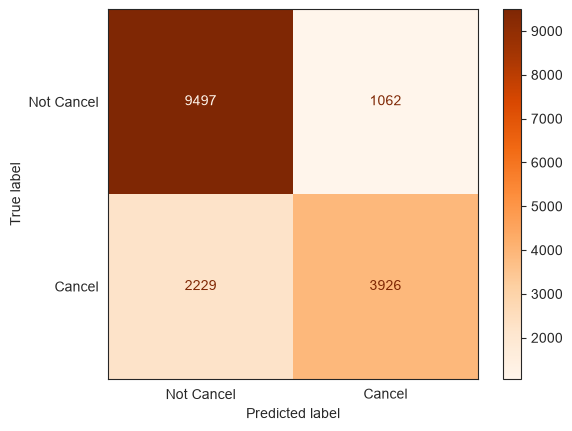

In [34]:
ConfusionMatrixDisplay.from_predictions(y_val, y_pred_lgb, values_format='d', display_labels=cm_label, cmap='Oranges')

##### Gradient Boost

In [44]:
model_gb = pickle.load(open(path+'Mod_GradientBoost_N_First_Tune.sav', 'rb'))
model_gb

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('modeling', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['market_seg','deposit_type','customer_type',...,'months_wait_list', 'continent','is_domestic']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('onehot', ...), ('scaler_months', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By spe

In [37]:
# GBoost
model_gb.fit(X_train, y_train)

# Predict
y_pred_gb = model_gb.predict(X_val)

print('F bscore train: ', fbeta_score(y_train, model_gb.predict(X_train), beta=0.5) )
print('F bscore validate: ', fbeta_score(y_val, model_gb.predict(X_val), beta=0.5) )

F bscore train:  0.7583230579531443
F bscore validate:  0.7501052712169353


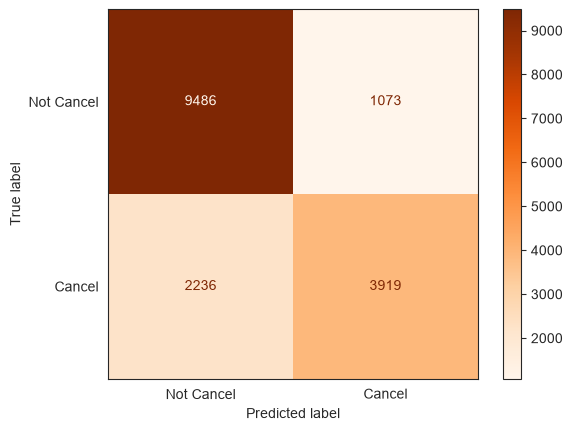

In [38]:
ConfusionMatrixDisplay.from_predictions(y_val, y_pred_gb, values_format='d', display_labels=cm_label, cmap='Oranges')

#### Model Trials

##### First Model

`Features:`\
'continent', 'market_segment', 'previous_cancellations', 'booking_changes', 'deposit_type', 'months_wait_list',\
'customer_type', 'reserved_room_type', 'required_car_parking_spaces', 'total_of_special_requests'

Benchmark Model:\
GradientBoost and XGradientBoost give better F-score (beta = 0.5) with 75.4 - 75.5%.

**Model algorithm: Gradient Boost**\
Parameters:\
{'modeling__learning_rate': 0.01, 'modeling__max_depth': 3, 'modeling__min_samples_leaf': 3,\
 'modeling__n_estimators': 1000, 'modeling__subsample': 0.6,\
 'preprocessing__scaler_discrete': MinMaxScaler(), 'preprocessing__scaler_months': MinMaxScaler()}\
Metrics:\
F-bscore train:  75.83 | F-bscore validate:  75.19\
F-bscore test:  75.66 | Precision test:  80.57 | Recall test:  60.83

**Model algorithm: XGradient Boost**\
Parameters:\
{'modeling__grow_policy': 'depthwise', 'modeling__n_estimators': 500,\
'modeling__sampling_method': 'uniform', 'modeling__subsample': 0.7,\
'preprocessing__scaler_discrete': MinMaxScaler(), 'preprocessing__scaler_months': MinMaxScaler()}\
Metrics:\
F-bscore train:  75.78 | F-bscore validate:  75.16\
F bscore test: 75.58 | Precision test: 80.53 | Recall test: 60.67

Feature Importance for Room Type are really low: Type A = 0.002983 | Type G = 0.001155 | Rest below 0.001\
Features will be generalized and re-model.

##### Second Model

`Features:`\
'market_seg', 'deposit_type', 'customer_type', 'spec_requests', 'previous_cancel',\
'is_booking_changes', 'is_req_parking', 'months_wait_list', 'continent', 'is_domestic'

Benchmark Model:\
GradientBoost and LightGBoost give better F-score (beta = 0.5) with 75.5 - 75.6%.

**Model Algorithm: Light Gradient Boost**\
Parameters:\
{learning_rate=0.01, 'modeling__boosting_type': 'dart', 'modeling__n_estimators': 1000, 'modeling__colsample_bytree': 0.6, 'modeling__subsample': 0.8,\
'preprocessing__scaler_months': MinMaxScaler()}\
F-bscore train: 76.11 | F-bscore validate: 75.19\
F bscore test: 76.01 | Precision test: 79.49 | Recall test: 64.68

**Model Algorithm: Gradient Boost**\
Parameters:\
{learning_rate=0.01, 'modeling__max_depth': 3, 'modeling__min_samples_leaf': 5, 'modeling__n_estimators': 1000, 'modeling__subsample': 1,\
'preprocessing__scaler_months': MinMaxScaler()}\
F bscore train: 75.83 | F bscore validate: 75.01\
F bscore test: 75.68 | Precision test: 79.10 | Recall test: 64.55

##### Chosen Algorithm

Light Gradient Boost, with adjusted features.

#### Second Hyperparameter Tuning

In [277]:
X.columns

Index(['market_seg', 'deposit_type', 'customer_type', 'spec_requests',
       'previous_cancel', 'is_booking_changes', 'is_req_parking',
       'months_wait_list', 'continent', 'is_domestic'],
      dtype='str')

In [ ]:
# Redefine Pipeline

transformer = ColumnTransformer([
    ('onehot', OneHotEncoder(handle_unknown='error'),
     ['market_seg', 'deposit_type','customer_type', 'previous_cancel', 'spec_requests', 'continent'] ),
    ('scaler_months', MinMaxScaler(), ['months_wait_list'])
], remainder='passthrough') # 'is_booking_changes', 'is_req_parking', 'is_domestic'

transformer

In [278]:
?LGBMClassifier

Init signature:
LGBMClassifier(
    *,
    boosting_type: str = 'gbdt',
    num_leaves: int = 31,
    max_depth: int = -1,
    learning_rate: float = 0.1,
    n_estimators: int = 100,
    subsample_for_bin: int = 200000,
    objective: str | Callable[[numpy.ndarray | None, numpy.ndarray], Tuple[numpy.ndarray, numpy.ndarray]] | Callable[[numpy.ndarray | None, numpy.ndarray, numpy.ndarray | None], Tuple[numpy.ndarray, numpy.ndarray]] | Callable[[numpy.ndarray | None, numpy.ndarray, numpy.ndarray | None, numpy.ndarray | None], Tuple[numpy.ndarray, numpy.ndarray]] | None = None,
    class_weight: Dict | str | None = None,
    min_split_gain: float = 0.0,
    min_child_weight: float = 0.001,
    min_child_samples: int = 20,
    subsample: float = 1.0,
    subsample_freq: int = 0,
    colsample_bytree: float = 1.0,
    reg_alpha: float = 0.0,
    reg_lambda: float = 0.0,
    random_state: numpy.random.mtrand.RandomState | numpy.random._generator.Generator | int | None = None,
    n_jobs: int

In [21]:
# Find best n_estimators
import lightgbm as lgb

X_train_trf = transformer.fit_transform(X_train)
X_val_trf = transformer.transform(X_val)

mod_lgb = LGBMClassifier( n_estimators=5000, learning_rate=0.01, verbosity=-1, random_state=13)

mod_lgb.fit( X_train_trf, y_train,
             eval_X = X_val_trf,
             eval_y = y_val,
             eval_metric='auc',
             callbacks=[lgb.early_stopping(750)]
         )

Training until validation scores don't improve for 750 rounds
Early stopping, best iteration is:
[1485]	valid_0's auc: 0.88331	valid_0's binary_logloss: 0.37905


,learning_rate,0.01
,n_estimators,5000
,random_state,13
,verbosity,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0


540 auc: 0.882466 (don't improve for 50 rounds)\
816 auc: 0.883026 (don't improve for 100 rounds)\
1.485 auc: 0.88331 (don't improve for 500 rounds)\
1.485 auc: 0.88331 (don't improve for 750 rounds)

In [96]:
# Define pipeline for Hyperparameter Tuning

mod_lgb = LGBMClassifier(n_estimators = 1485, learning_rate = 0.01,
                         subsample_freq = 1, max_depth = -1, random_state = 13) 

# Pipeline
pipe_prep_model_lgb =  Pipeline([
    ('preprocessing', transformer),
    ('modeling', mod_lgb)
])
   
# Hyperparameters
hyperparams = {'modeling__min_child_samples' : [5, 20, 50],
               'modeling__boosting_type' : ['gbdt', 'dart'],
               'modeling__num_leaves' : [31, 63, 127],
               'modeling__colsample_bytree' : [0.6, 0.8],
               'modeling__subsample' : [0.6, 0.8]
             }
   
# Method: Grid search
gridsearch_lgb = GridSearchCV(
    estimator = pipe_prep_model_lgb,
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=13),
    n_jobs = -1,
    param_grid= hyperparams,
    scoring = f_bscore,
    error_score = 'raise'
)

In [97]:
print( len(ParameterGrid(hyperparams)) )

72


In [98]:
%%time
gridsearch_lgb.fit(X_train, y_train)

CPU times: total: 9min 16s
Wall time: 1h 46min 48s


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...ple_freq=1))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'modeling__boosting_type': ['gbdt', 'dart'], 'modeling__colsample_bytree': [0.6, 0.8], 'modeling__min_child_samples': [5, 20, ...], 'modeling__num_leaves': [31, 63, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","make_scorer(f...ct', beta=0.5)"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"error_score error_score: 'raise' or numeric, default=np.nanValue to assign to the score if an error occurs in estimator fitting.If set to 'raise', the error is raised. If a numeric value is given,FitFailedWarning is raised. This parameter does not affect the refitstep, which will always raise the error.",'raise'
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metriceval

In [104]:
# N_F1 >> subsample_freq = 0, subsample = 1, colsample = 0.6, 0.8
# N_F2 >> subsample_freq = 1, subsample = 0.6, 0.8, colsample = 0.6, 0.8, add min_child = 5 & num_leaves = 127

# model_best = gridsearch_lgb.best_estimator_
# pickle.dump(model_best, open(path+'Mod_LGBoost_N_F2.sav', 'wb'))

In [106]:
results_gbF = pd.read_csv(path + "Grid_Search_lgb_Second_Tuned.csv")
results_gbF = results_gbF.sort_values(by='mean_test_score', ascending=False)
results_gbF.head(5)

,Unnamed: 0,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_modeling__boosting_type,param_modeling__colsample_bytree,param_modeling__min_child_samples,param_modeling__num_leaves,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score,param_modeling__subsample
0,0,466.722166,27.970212,0.425137,0.026321,dart,0.6,50,63,"{'modeling__boosting_type': 'dart', 'modeling__colsample_bytree': 0.6, 'modeling__min_child_samples': 50, 'modeling__num_leaves': 63, 'modeling__subsample': 0.6}",0.759251,0.763411,0.758903,0.754106,0.763859,0.759906,0.003549,1,0.6
1,1,539.339511,15.751987,0.496122,0.039862,dart,0.6,50,127,"{'modeling__boosting_type': 'dart', 'modeling__colsample_bytree': 0.6, 'modeling__min_child_samples': 50, 'modeling__num_leaves': 127, 'modeling__subsample': 0.6}",0.759251,0.763411,0.758903,0.754106,0.763859,0.759906,0.003549,1,0.6
2,2,638.794641,10.551081,0.458699,0.023968,dart,0.6,50,127,"{'modeling__boosting_type': 'dart', 'modeling__colsample_bytree': 0.6, 'modeling__min_child_samples': 50, 'modeling__num_leaves': 127, 'modeling__subsample': 0.8}",0.759498,0.762449,0.759401,0.753841,0.763535,0.759745,0.003368,3,0.8
3,3,483.317967,37.567314,0.442801,0.043707,dart,0.6,50,63,"{'modeling__boosting_type': 'dart', 'modeling__colsample_bytree': 0.6, 'modeling__min_child_samples': 50, 'modeling__num_leaves': 63, 'modeling__subsample': 0.8}",0.759498,0.762449,0.759209,0.753841,0.763535,0.759706,0.003372,4,0.8
4,4,605.366527,10.903957,0.524131,0.050587,dart,0.6,50,63,"{'modeling__boosting_type': 'dart', 'modeling__colsample_bytree': 0.6, 'modeling__min_child_samples': 50, 'modeling__num_leaves': 63}",0.759128,0.762471,0.759594,0.753639,0.762785,0.759523,0.003290,1,NaN


The model performed well with subsample row of 0.6, 0.8, and 1; with both num_leaves 63 and 127.

##### Validate Model

In [46]:
mod_lgb = pickle.load(open(path + 'Mod_LGBoost_N_Second_Tune.sav', 'rb'))

mod_lgb.get_params()

{'memory': None,
 'steps': [('preprocessing',
   ColumnTransformer(remainder='passthrough',
                     transformers=[('onehot', OneHotEncoder(),
                                    ['market_seg', 'deposit_type', 'customer_type',
                                     'previous_cancel', 'spec_requests',
                                     'continent']),
                                   ('scaler_months', MinMaxScaler(),
                                    ['months_wait_list'])])),
  ('modeling',
   LGBMClassifier(boosting_type='dart', colsample_bytree=0.6, learning_rate=0.01,
                  min_child_samples=50, n_estimators=1485, num_leaves=63,
                  random_state=13, subsample=0.6, subsample_freq=1))],
 'transform_input': None,
 'verbose': False,
 'preprocessing': ColumnTransformer(remainder='passthrough',
                   transformers=[('onehot', OneHotEncoder(),
                                  ['market_seg', 'deposit_type', 'customer_type',
              

In [109]:
mod_lgb = pickle.load(open(path + 'Mod_LGBoost_N_Second_Tune.sav', 'rb'))
s_row = [0.6, 0.8, 1]
s_freq = [1, 1, 0]

Test_Score = {
    'Subsample Row' : [],
    'F-score Train' : [],
    'F-score Val' : [],
    'F-score Test' : [],
    'Params' : []
}

for idx in range(0, len(s_row)):

    mod_lgb.named_steps['modeling'].set_params(
        subsample = s_row[idx],
        subsample_freq = s_freq[idx]
    )

    mod_lgb.fit(X_train, y_train)
    
    Test_Score['Subsample Row'].append(s_row[idx])
    Test_Score['F-score Train'].append( fbeta_score(y_train, mod_lgb.predict(X_train), beta=0.5) )
    Test_Score['F-score Val'].append( fbeta_score(y_val, mod_lgb.predict(X_val), beta=0.5) )
    Test_Score['F-score Test'].append( fbeta_score(y_test, mod_lgb.predict(X_test), beta=0.5) )
    Test_Score['Params'].append(mod_lgb.named_steps['modeling'].get_params() )

pd.DataFrame(Test_Score).sort_values(by='F-score Test', ascending=False)
    

,Subsample Row,F-score Train,F-score Val,F-score Test,Params
0,0.6,0.760723,0.751737,0.760227,"{'boosting_type': 'dart', 'class_weight': None, 'colsample_bytree': 0.6, 'importance_type': 'split', 'learning_rate': 0.01, 'max_depth': -1, 'min_child_samples': 50, 'min_child_weight': 0.001, 'min_split_gain': 0.0, 'n_estimators': 1485, 'n_jobs': None, 'num_leaves': 63, 'objective': None, 'random_state': 13, 'reg_alpha': 0.0, 'reg_lambda': 0.0, 'subsample': 0.6, 'subsample_for_bin': 200000, 'subsample_freq': 1}"
2,1.0,0.760725,0.751851,0.760012,"{'boosting_type': 'dart', 'class_weight': None, 'colsample_bytree': 0.6, 'importance_type': 'split', 'learning_rate': 0.01, 'max_depth': -1, 'min_child_samples': 50, 'min_child_weight': 0.001, 'min_split_gain': 0.0, 'n_estimators': 1485, 'n_jobs': None, 'num_leaves': 63, 'objective': None, 'random_state': 13, 'reg_alpha': 0.0, 'reg_lambda': 0.0, 'subsample': 1, 'subsample_for_bin': 200000, 'subsample_freq': 0}"
1,0.8,0.760750,0.751851,0.759897,"{'boosting_type': 'dart', 'class_weight': None, 'colsample_bytree': 0.6, 'importance_type': 'split', 'learning_rate': 0.01, 'max_depth': -1, 'min_child_samples': 50, 'min_child_weight': 0.001, 'min_split_gain': 0.0, 'n_estimators': 1485, 'n_jobs': None, 'num_leaves': 63, 'objective': None, 'random_state': 13, 'reg_alpha': 0.0, 'reg_lambda': 0.0, 'subsample': 0.8, 'subsample_for_bin': 200000, 'subsample_freq': 1}"


In [112]:
mod_lgb = pickle.load(open(path + 'Mod_LGBoost_N_Second_Tune.sav', 'rb'))
n_child = [5, 20, 50]
n_leaves = [127, 63, 63]

Test_Score = {
    'Min Child' : [],
    'Max Leaves' : [],
    'F-score Train' : [],
    'F-score Val' : [],
    'F-score Test' : [],
    'Params' : []
}

for idx in range(0, len(n_child)):

    mod_lgb.named_steps['modeling'].set_params(
        subsample = 0.6, subsample_freq = 1,
        min_child_samples = n_child[idx],
        num_leaves = n_leaves[idx]
    )

    mod_lgb.fit(X_train, y_train)
        
    Test_Score['Min Child'].append(n_child[idx])
    Test_Score['Max Leaves'].append(n_leaves[idx])
    Test_Score['F-score Train'].append( fbeta_score(y_train, mod_lgb.predict(X_train), beta=0.5) )
    Test_Score['F-score Val'].append( fbeta_score(y_val, mod_lgb.predict(X_val), beta=0.5) )
    Test_Score['F-score Test'].append( fbeta_score(y_test, mod_lgb.predict(X_test), beta=0.5) )
    Test_Score['Params'].append(mod_lgb.named_steps['modeling'].get_params() )

pd.DataFrame(Test_Score).sort_values(by='F-score Test', ascending=False)
    

,Min Child,Max Leaves,F-score Train,F-score Val,F-score Test,Params
1,20,63,0.761128,0.751777,0.760268,"{'boosting_type': 'dart', 'class_weight': None, 'colsample_bytree': 0.6, 'importance_type': 'split', 'learning_rate': 0.01, 'max_depth': -1, 'min_child_samples': 20, 'min_child_weight': 0.001, 'min_split_gain': 0.0, 'n_estimators': 1485, 'n_jobs': None, 'num_leaves': 63, 'objective': None, 'random_state': 13, 'reg_alpha': 0.0, 'reg_lambda': 0.0, 'subsample': 0.6, 'subsample_for_bin': 200000, 'subsample_freq': 1}"
2,50,63,0.760723,0.751737,0.760227,"{'boosting_type': 'dart', 'class_weight': None, 'colsample_bytree': 0.6, 'importance_type': 'split', 'learning_rate': 0.01, 'max_depth': -1, 'min_child_samples': 50, 'min_child_weight': 0.001, 'min_split_gain': 0.0, 'n_estimators': 1485, 'n_jobs': None, 'num_leaves': 63, 'objective': None, 'random_state': 13, 'reg_alpha': 0.0, 'reg_lambda': 0.0, 'subsample': 0.6, 'subsample_for_bin': 200000, 'subsample_freq': 1}"
0,5,127,0.757151,0.746380,0.755742,"{'boosting_type': 'dart', 'class_weight': None, 'colsample_bytree': 0.6, 'importance_type': 'split', 'learning_rate': 0.01, 'max_depth': -1, 'min_child_samples': 5, 'min_child_weight': 0.001, 'min_split_gain': 0.0, 'n_estimators': 1485, 'n_jobs': None, 'num_leaves': 127, 'objective': None, 'random_state': 13, 'reg_alpha': 0.0, 'reg_lambda': 0.0, 'subsample': 0.6, 'subsample_for_bin': 200000, 'subsample_freq': 1}"


**Choosen Model**

In [120]:
# Readjust parameters
model_lgb = pickle.load(open(path + 'Mod_LGBoost_N_Second_Tune.sav', 'rb'))

model_lgb.named_steps['modeling'].set_params(
        subsample = 0.6, subsample_freq = 1,
        min_child_samples = 20, num_leaves = 63)

model_lgb.fit(X_train, y_train)

pickle.dump(model_lgb, open(path+'Mod_LGBoost_Hotel_Booking.sav', 'wb'))

In [14]:
# Final Chosen Model
model_lgb = pickle.load(open(path + 'Mod_LGBoost_Hotel_Booking.sav', 'rb'))

In [15]:
model_lgb.get_params()

{'memory': None,
 'steps': [('preprocessing',
   ColumnTransformer(remainder='passthrough',
                     transformers=[('onehot', OneHotEncoder(),
                                    ['market_seg', 'deposit_type', 'customer_type',
                                     'previous_cancel', 'spec_requests',
                                     'continent']),
                                   ('scaler_months', MinMaxScaler(),
                                    ['months_wait_list'])])),
  ('modeling',
   LGBMClassifier(boosting_type='dart', colsample_bytree=0.6, learning_rate=0.01,
                  n_estimators=1485, num_leaves=63, random_state=13, subsample=0.6,
                  subsample_freq=1))],
 'transform_input': None,
 'verbose': False,
 'preprocessing': ColumnTransformer(remainder='passthrough',
                   transformers=[('onehot', OneHotEncoder(),
                                  ['market_seg', 'deposit_type', 'customer_type',
                                   '

In [16]:
# Check tree structure of the model
tree_df = model_lgb[-1].booster_.trees_to_dataframe()

In [17]:
tree_df.head()

,tree_index,node_depth,node_index,left_child,right_child,parent_index,split_feature,split_gain,threshold,decision_type,missing_direction,missing_type,value,weight,count
0,0,1,0-S0,0-S17,0-S1,NaN,Column_7,6858.609863,1.000000e-35,<=,left,None,-0.044901,6988.520000,30039
1,0,2,0-S17,0-S18,0-S46,0-S0,Column_32,49.944801,1.000000e-35,<=,left,None,-0.042692,854.517000,3673
2,0,3,0-S18,0-L0,0-L19,0-S17,Column_13,106.512001,1.000000e-35,<=,left,None,-0.043769,28.848400,124
3,0,4,0-L0,NaN,NaN,0-S18,NaN,NaN,NaN,NaN,NaN,NaN,-0.042726,20.240401,87
4,0,4,0-L19,NaN,NaN,0-S18,NaN,NaN,NaN,NaN,NaN,NaN,-0.046220,8.607986,37


In [202]:
import re
leaf_right = []
leaf_left = []

pat = r"\d-\D(\d{1,2})"   # Last: '1484-L59'

for uniq in tree_df['right_child'].unique():
    if type(uniq)==str:
        result = re.findall(pattern=pat, string=uniq)
        leaf_right.append( int(*result) )
    else:
        leaf_right.append(0)

for uniq in tree_df['left_child'].unique():
    if type(uniq)==str:
        result = re.findall(pattern=pat, string=uniq)
        leaf_left.append( int(*result) )
    else:
        leaf_left.append(0)

print('Min Leaf right: ', min(leaf_right), '\tMax Leaf right: ', max(leaf_right) )
print('Min Leaf left: ', min(leaf_left), '\tMax Leaf left: ', max(leaf_left) )

Min Leaf right:  0 	Max Leaf right:  62
Min Leaf left:  0 	Max Leaf left:  61


In [117]:
tree_df.describe()

,tree_index,node_depth,split_gain,threshold,value,weight,count
count,185469.000000,185469.000000,9.199200e+04,9.199200e+04,185469.000000,185469.000000,185469.000000
mean,741.662758,7.993945,3.607135e+01,1.425542e-02,-0.000568,425.636554,2174.088209
std,428.598004,2.647717,2.130536e+02,7.093490e-02,0.002800,919.349792,4577.393743
min,0.000000,1.000000,2.799980e-13,1.000000e-35,-0.046220,0.284526,2.000000
25%,371.000000,6.000000,6.453402e-01,1.000000e-35,-0.001100,13.521599,85.000000
50%,741.000000,8.000000,1.975015e+00,1.000000e-35,-0.000135,73.203800,446.000000
75%,1113.000000,10.000000,8.318268e+00,1.000000e-35,0.000030,365.326301,2034.000000
max,1484.000000,19.000000,6.860290e+03,5.769231e-01,0.025487,7498.640000,30519.000000


Total tree = 1.484 | Max depth = 19 | Max num leaves = 63

In [123]:
# Light GradientBoosting

print('F bscore train: ', fbeta_score(y_train, model_lgb.predict(X_train), beta=0.5) )
print('F bscore validate: ', fbeta_score(y_val, model_lgb.predict(X_val), beta=0.5) )
print('F bscore test: ', fbeta_score(y_test, model_lgb.predict(X_test), beta=0.5) )

F bscore train:  0.7611279305426977
F bscore validate:  0.7517768233818555
F bscore test:  0.7602682631100334


In [124]:
print('Precision test: ', precision_score(y_test, model_lgb.predict(X_test)) )
print('Recall test: ', recall_score(y_test, model_lgb.predict(X_test)) )

Precision test:  0.7932397707056731
Recall test:  0.6518843404808317


In [19]:
from sklearn.metrics import roc_curve, RocCurveDisplay

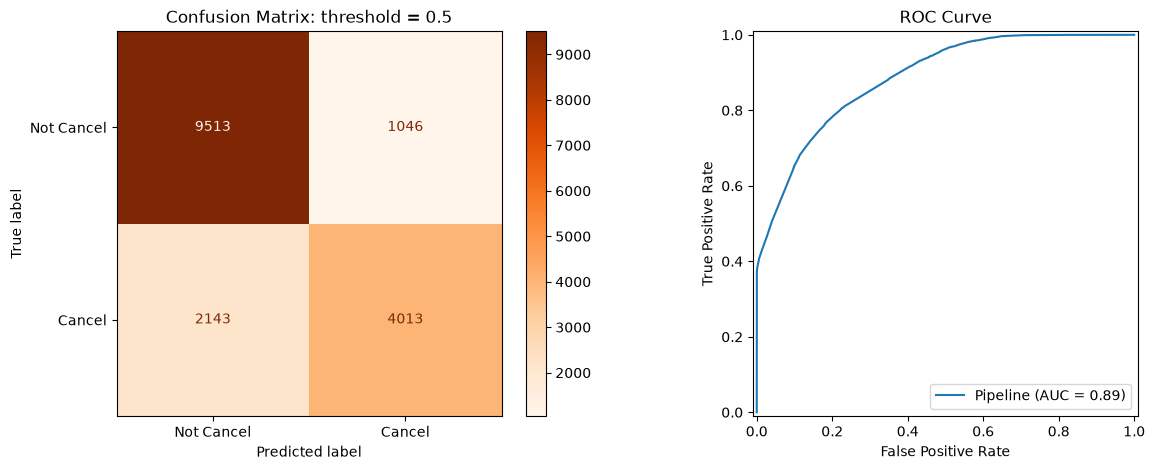

In [22]:
# Predict test data
y_pred = model_lgb.predict(X_test)

fig, axes = plt.subplots(1,2, figsize=(14,5))
cm_label = ['Not Cancel', 'Cancel']

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, values_format='d', display_labels=cm_label, cmap='Oranges', ax=axes[0])
axes[0].set_title('Confusion Matrix: threshold = 0.5')

RocCurveDisplay.from_estimator(model_lgb, X_test, y_test, ax=axes[1])
axes[1].set_title('ROC Curve')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')

plt.show()

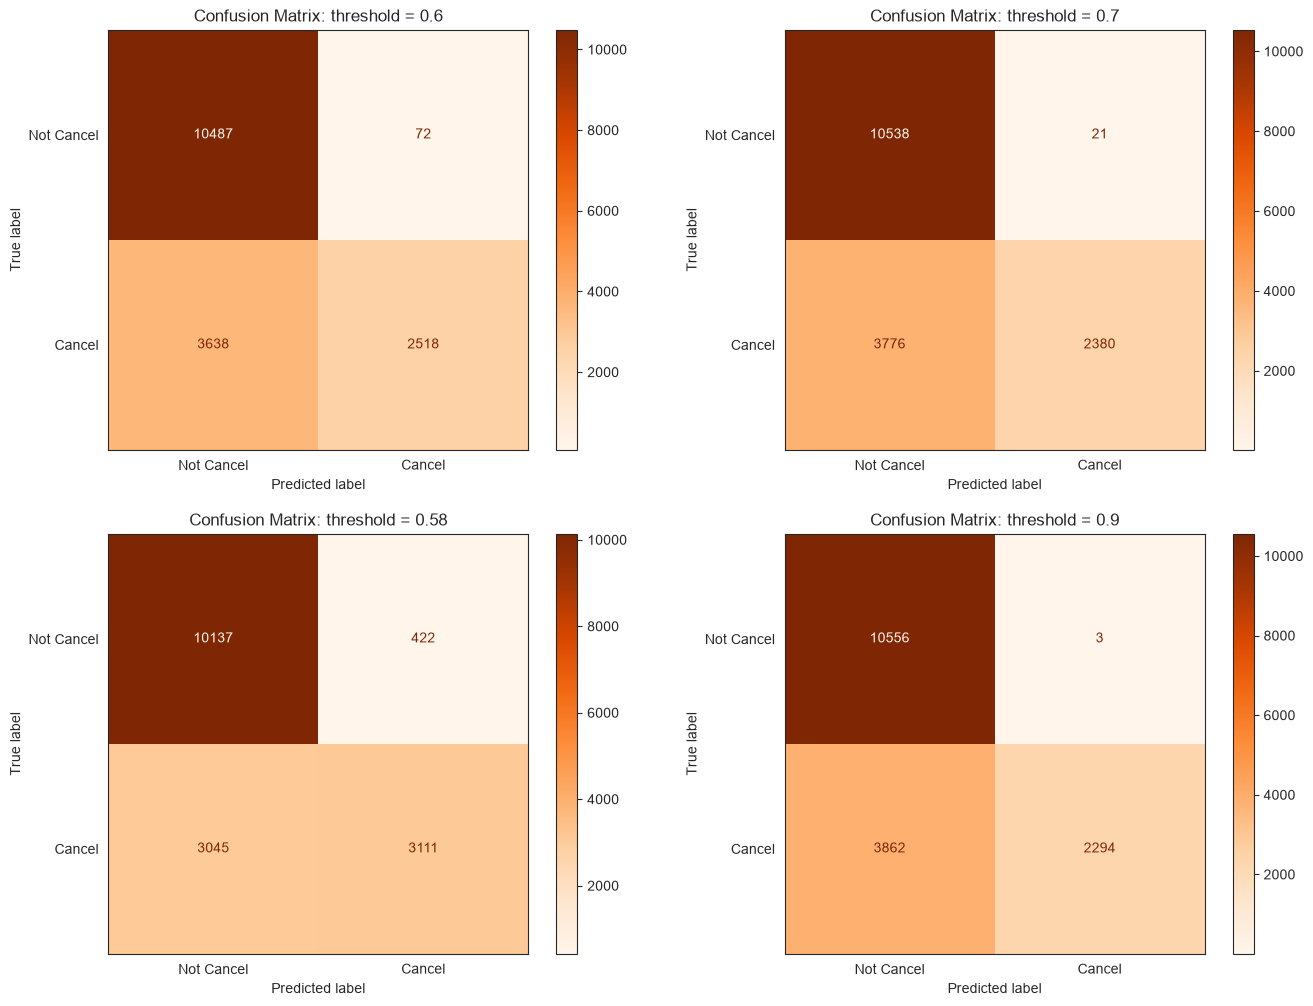

In [26]:
sns.set_style('white')
fig, axes = plt.subplots(2,2, figsize=(16,12))
cm_label = ['Not Cancel', 'Cancel']

y_pred_proba = model_lgb.predict_proba(X_test)[:,1]

y_pred_t1 = np.where(y_pred_proba > 0.6, 1, 0)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_t1, values_format='d', display_labels=cm_label, cmap='Oranges', ax=axes[0,0])
axes[0,0].set_title('Confusion Matrix: threshold = 0.6')

y_pred_t2 = np.where(y_pred_proba > 0.7, 1, 0)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_t2, values_format='d', display_labels=cm_label, cmap='Oranges', ax=axes[0,1])
axes[0,1].set_title('Confusion Matrix: threshold = 0.7')

y_pred_t3 = np.where(y_pred_proba > 0.58, 1, 0)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_t3, values_format='d', display_labels=cm_label, cmap='Oranges', ax=axes[1,0])
axes[1,0].set_title('Confusion Matrix: threshold = 0.58')

y_pred_t4 = np.where(y_pred_proba > 0.9, 1, 0)
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_t4, values_format='d', display_labels=cm_label, cmap='Oranges', ax=axes[1,1])
axes[1,1].set_title('Confusion Matrix: threshold = 0.9')

plt.show()

**Threshold**

To align with the business goal (model with low False Positive Rate), the model works better with threshold 0.70.\
However, the final decision will be in stakeholders.

In [132]:
# Column/Features name after transformed; access to pipeline
feature_name = model_lgb[-2].get_feature_names_out().tolist()
print ( feature_name, end=' ' )

['onehot__market_seg_Aviation', 'onehot__market_seg_Complementary', 'onehot__market_seg_Corporate', 'onehot__market_seg_Direct', 'onehot__market_seg_Groups', 'onehot__market_seg_Offline TA/TO', 'onehot__market_seg_Online TA', 'onehot__deposit_type_No Deposit', 'onehot__deposit_type_Non Refund', 'onehot__deposit_type_Refundable', 'onehot__customer_type_Contract', 'onehot__customer_type_Group', 'onehot__customer_type_Transient', 'onehot__customer_type_Transient-Party', 'onehot__previous_cancel_Cancel_0', 'onehot__previous_cancel_Cancel_1', 'onehot__previous_cancel_Cancel_14', 'onehot__previous_cancel_Cancel_2_13', 'onehot__spec_requests_0', 'onehot__spec_requests_1', 'onehot__spec_requests_2', 'onehot__spec_requests_3', 'onehot__spec_requests_4', 'onehot__spec_requests_5', 'onehot__continent_Africa', 'onehot__continent_America', 'onehot__continent_Asia', 'onehot__continent_Europe', 'onehot__continent_Oceania', 'scaler_months__months_wait_list', 'remainder__is_booking_changes', 'remainder

In [133]:
# Feature importance (LGB: Gain Importance); to construct decision tree
gain_imp = model_lgb[-1].booster_.feature_importance(importance_type = 'gain')

split_counts = model_lgb[1].feature_importances_
imp_pct = split_counts / split_counts.sum() * 100

df_feature_imp = pd.DataFrame(
    {'Feature Name' : feature_name,
    'Gain Importance' : gain_imp,
    'Split Counts' : split_counts,
    'Percentage' : imp_pct}
)

df_feature_imp = df_feature_imp.sort_values(by='Split Counts', ascending=False).reset_index(drop=True)
df_feature_imp

,Feature Name,Gain Importance,Split Counts,Percentage
0,remainder__is_booking_changes,85674.338764,6388,6.944082
1,scaler_months__months_wait_list,19091.418113,5957,6.475563
2,onehot__customer_type_Transient-Party,72226.899100,5738,6.237499
3,onehot__customer_type_Transient,141381.884705,5488,5.965736
4,onehot__continent_Europe,17325.880109,5229,5.684190
5,onehot__spec_requests_1,41416.343677,5018,5.454822
6,onehot__spec_requests_0,196993.820178,4430,4.815636
7,onehot__spec_requests_2,31187.482514,4400,4.783025
8,onehot__market_seg_Offline TA/TO,99774.650870,4041,4.392773
9,onehot__continent_Asia,8626.776909,3906,4.246021


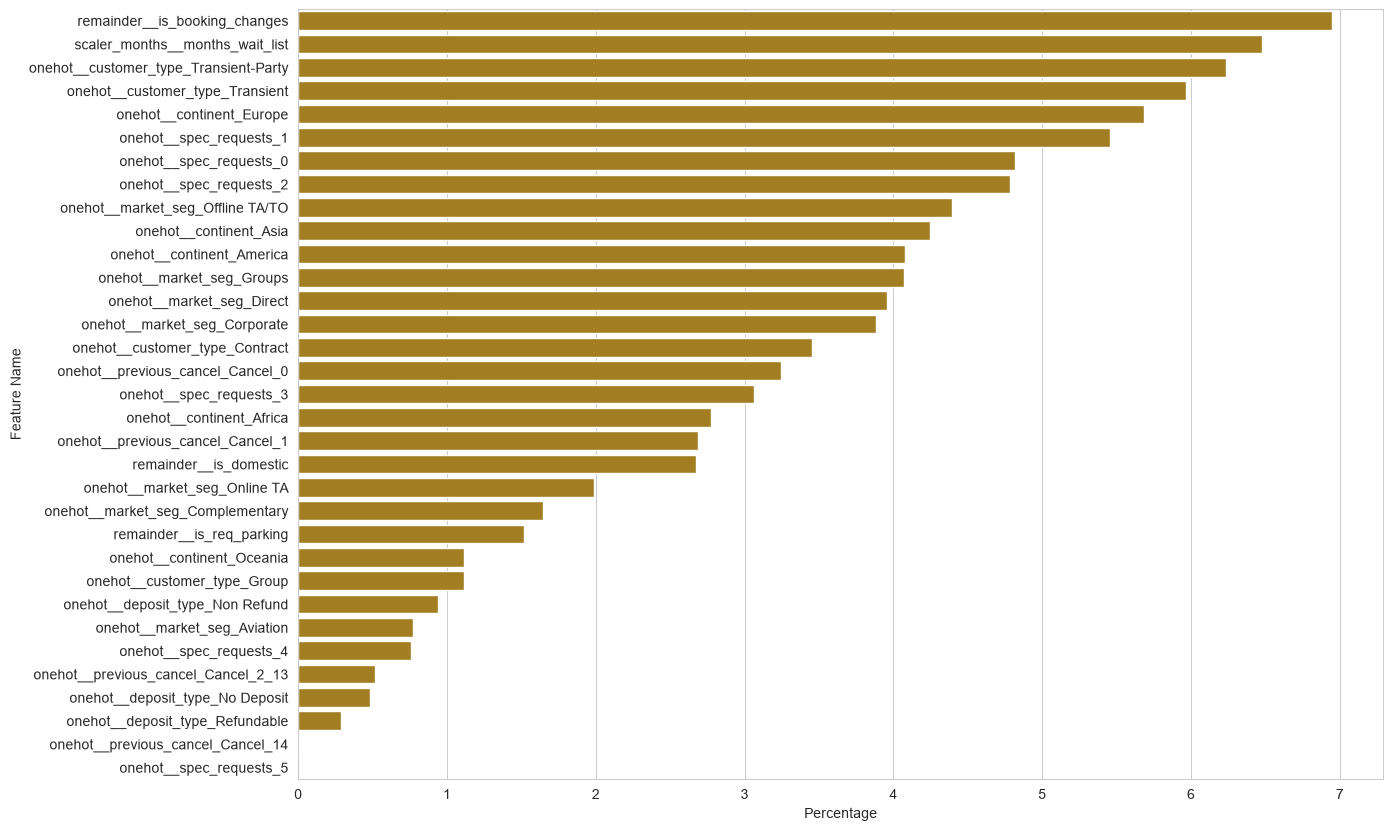

In [135]:
# Split optimization in LightGB Classifier: Log-loss (deviance)
# log-loss (the penalty for wrong or over‑confident predictions)
sns.set_style('whitegrid')
plt.figure(figsize=(14,10))
ax = sns.barplot(data=df_feature_imp, x='Percentage', y='Feature Name', color='darkgoldenrod')
ax.set_xticklabels = [range(0,11,1)]

plt.savefig(path + "Mod_LGBoost_Hotel_Booking_F_Importance.png", dpi=300, bbox_inches="tight")
plt.show()

During modeling process, the most used features are: Customer Type, Booking Changes, Previous Cancelations, and Market Segment.\
These are features with the most usage to build the trees. 

### Model Interpretation

In [136]:
# Import Library

# Shapley Value of Explanation (SHAP)
import shap 
shap.initjs() # Force plot SHAP

# Local Interpretable Model-agnostic Explanation (LIME)
import lime
from lime import lime_tabular

In [137]:
model_lgb = pickle.load(open(path + 'Mod_LGBoost_Hotel_Booking.sav', 'rb'))
model_lgb

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('modeling', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['market_seg','deposit_type','customer_type',...,'months_wait_list', 'continent','is_domestic']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('onehot', ...), ('scaler_months', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By spe

In [138]:
preprocessed = model_lgb.named_steps['preprocessing']
explain_model = model_lgb.named_steps['modeling']

# Transform data through preprocessing only
X_trf = preprocessed.transform(X_train)

X_test_trf = preprocessed.transform(X_test)

#### SHAP Explainer

##### Global Explainer

In [139]:
# Use TreeExplainer for tree-based models
shap_Expl = shap.TreeExplainer(explain_model)

# Compute SHAP values for each rows in X_train 
shap_values = shap_Expl.shap_values(X_trf)

C:\Users\v-ste\AppData\Roaming\Python\Python314\site-packages\shap\explainers\_tree.py:579: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


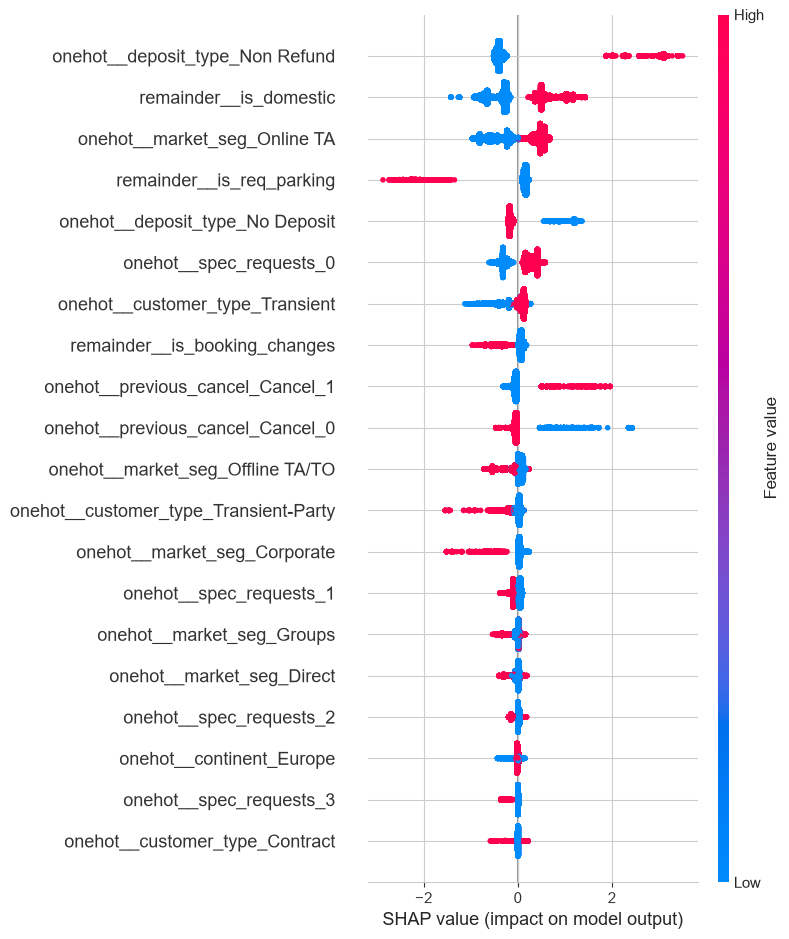

In [147]:
# SHAP Beeswarm Plot
shap.summary_plot(shap_values, X_trf, feature_names = feature_name, show=False)
plt.savefig(path + "Mod_LGBoost_Hotel_Booking_SHAP_Plot.png", bbox_inches="tight", dpi=300)

**Guest who will likely cancel bookings**
* Non refund guests
* Domestic guests
* Online Travel Agent
* Without Request Parking
* Without Special Requests
* Guests without cancel history and 1 cancel history

##### Local Explainer

In [141]:
# Compute SHAP values for each rows in X_test
shap_val_test = shap_Expl.shap_values(X_test_trf)

C:\Users\v-ste\AppData\Roaming\Python\Python314\site-packages\shap\explainers\_tree.py:579: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


The model must predict this customer will: Cancel their booking
Prediction probability:  [[0.0105858 0.9894142]]


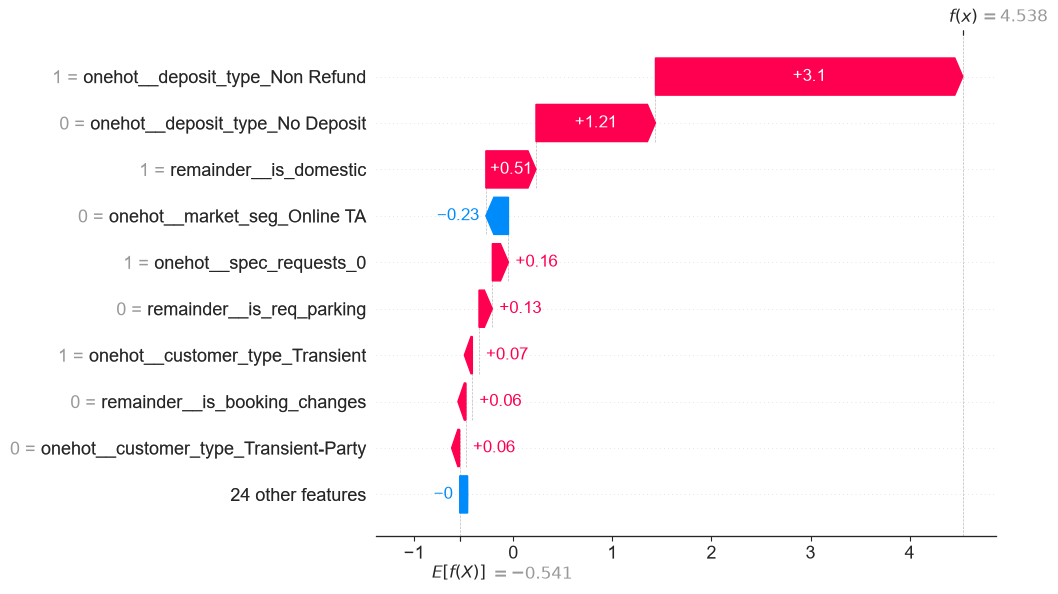

In [203]:
sns.set_style('white')

idx = 25
result = y_test.iloc[idx]

print(f"The model must predict this customer will: {('Cancel' if result == 1 else 'Not Cancel')} their booking")
print('Prediction probability: ', model_lgb[-1].predict_proba( X_test_trf[idx].reshape(1,-1) ) )

explanation = shap.Explanation(
    values=shap_val_test[idx],
    base_values=shap_Expl.expected_value,
    data=X_test_trf[idx],
    feature_names=feature_name
)

shap.plots.waterfall(explanation, max_display=10)

Major feature: Non Refund `Deposit Type`

The model must predict this customer will: Not Cancel their booking
Prediction probability:  [[0.97470967 0.02529033]]


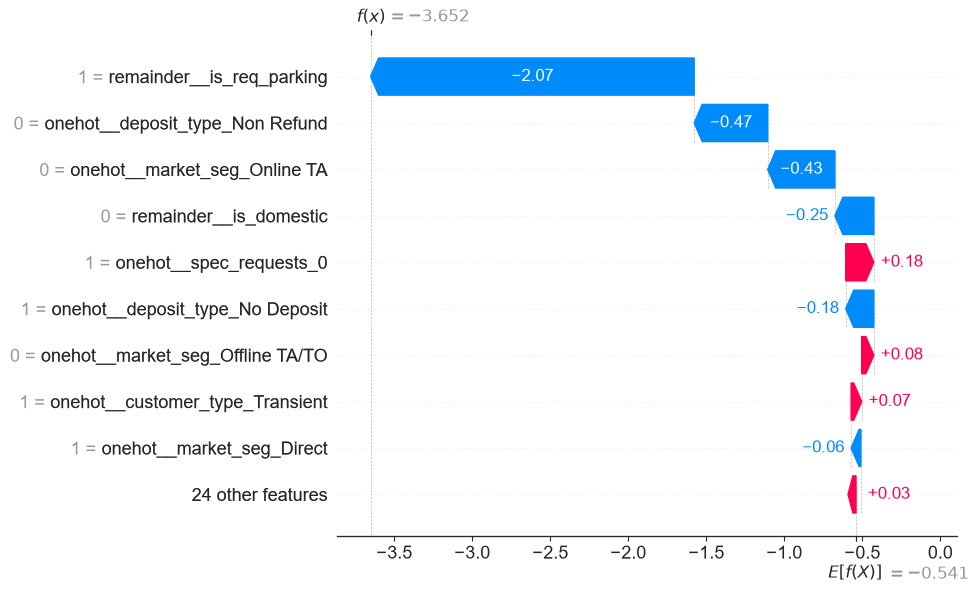

In [204]:
sns.set_style('white')

idx = 35
result = y_test.iloc[idx]

print(f"The model must predict this customer will: {('Cancel' if result == 1 else 'Not Cancel')} their booking")
print('Prediction probability: ', model_lgb[-1].predict_proba( X_test_trf[idx].reshape(1,-1) ) )

explanation = shap.Explanation(
    values=shap_val_test[idx],
    base_values=shap_Expl.expected_value,
    data=X_test_trf[idx],
    feature_names=feature_name
)

shap.plots.waterfall(explanation, max_display=10)

Major feature: Request Parking

#### LIME Local Explainer

In [144]:
# LIME Explainer
lime_Expl = lime_tabular.LimeTabularExplainer(
    training_data=X_trf,
    feature_names=feature_name,
    class_names=[': Not Canceled Bookings', ': Canceled Bookings'],  # ['Class0, Class1']
    mode='classification'
)

The model must predict this customer will: Cancel their booking
[[0.0105858 0.9894142]]


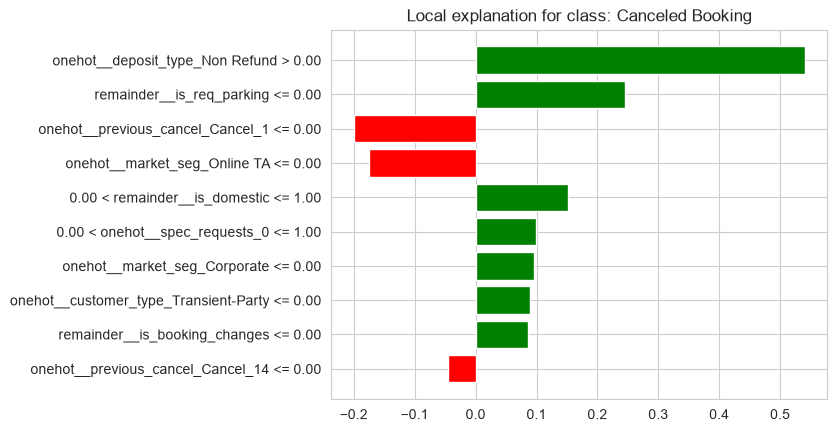

In [145]:
#LIME Explainer
idx = 25
result = y_test.iloc[idx]
X_test_trf = preprocessed.transform(X_test)

print(f"The model must predict this customer will: {('Cancel' if result == 1 else 'Not Cancel')} their booking")
print(model_lgb[-1].predict_proba( X_test_trf[idx].reshape(1,-1) ) )

exp = lime_Expl.explain_instance(data_row= X_test_trf[idx],    # X_test transformed
                                 predict_fn= model_lgb[-1].predict_proba,   # Called model only (without preprocess)
                                 labels=(0,1)
                                )

fig = exp.as_pyplot_figure(label=1)
plt.title('Local explanation for class: Canceled Booking')
plt.show()

The model must predict this customer will: Not Cancel their booking
[[0.97470967 0.02529033]]


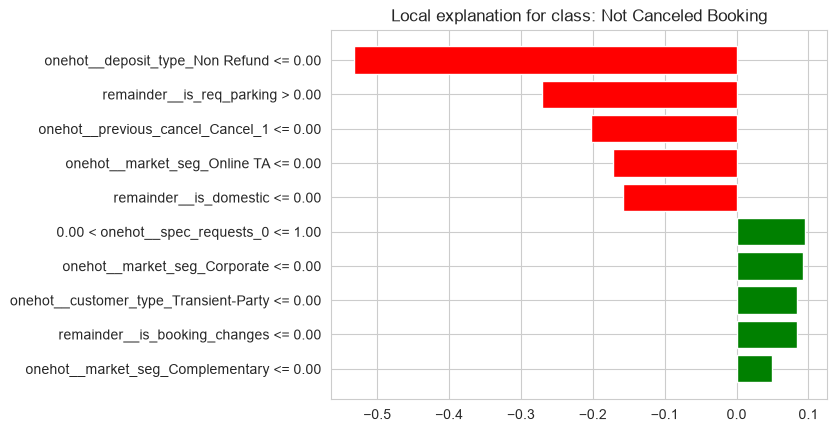

In [146]:
#LIME Explainer
idx = 35
result = y_test.iloc[idx]

print(f"The model must predict this customer will: {('Cancel' if result == 1 else 'Not Cancel')} their booking")
print(model_lgb[-1].predict_proba( X_test_trf[idx].reshape(1,-1) ) )

exp = lime_Expl.explain_instance(data_row= X_test_trf[idx],    # X_test transformed
                                 predict_fn= model_lgb[-1].predict_proba,   # Called model only (without preprocess)
                                 labels=(0,1)
                                )

fig = exp.as_pyplot_figure(label=1)
plt.title('Local explanation for class: Not Canceled Booking')
plt.show()

### Conclusion

#### Business Impact

Assumption:\
Average room rate	: EUR 70\
Booking deposit	: 30%

**Before Machine Learning**\
Canceled bookings : 6.156 bookings (from Test Data)\
= 6.156 bookings x EUR 21 (EUR 70 x 30%)\
= EUR 129k

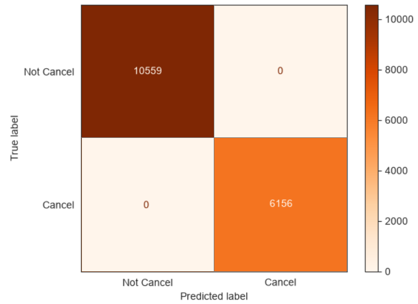

**After Machine Learning**\
If threshold is adjusted at 0.9 (extreme high):\
Canceled bookings : 3.862 bookings (from Test Data)\
Amount received from canceled bookings:\
= 3.862 bookings x EUR 21 (EUR 70 x 30%)\
= EUR 81k

Amount received from resell rooms:\
= 2.294 bookings x EUR 70 x 50% rooms\
= EUR 80k

Saved Amount  = 161k – 129k  =  **32k / year**\
This amount can be higher, if management/stakeholder decide to lower down threshold (as more True Positive predicted)

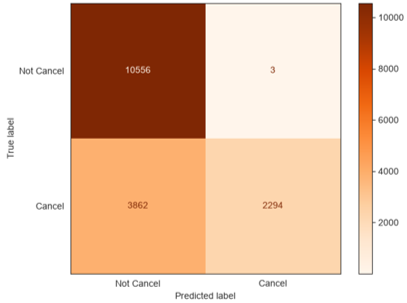

#### Recommendation

Customer who booked with 'No Refund Deposit' canceled their bookings mostly (99%).\
This issue can be solved by imply maximum check-in time for those bookings (Example: until 19:00 or early notice).\
After hotel guest do not show up, this room can be sold to another walk-in guests. Therefore, daily occupancy rate can be increased.

Data from marketing segment shown that "Group" segment has 61% of canceled bookings. This group consist of 42% transient and 53% transient-party.\
Marketing can make special "hotel deals" targeted to this group.  

#### Model Improvement

To improve this model to suit better for business decision and recommendation, it is essential to know about the daily occupancy rate.\
After knowing about this, it can be compared with the average occupancy rate of the city/country. Most of 4-star hotel recorded 70-80% daily occupancy rate in general. The number will be higher during high-season months, or lower during off-season.\
Therefore, `Staying_Date` date will be needed.

Additionally, `Staying_Month` will also increasing model performance, because we can understand if there are specific seasonal bookings pattern.\
Example: hotel guests will not cancel their bookings during high-season month, and vice-versa.\
This can be combined with National Holidays or School Holidays too.

If the hotel has membership, `Membership_Level` or `Membership_Status` also can be used to understand the customers behavior, and used as a feature to predict.

#### Model Limitation

As the model used manual binnings to categorized several features, several code-adjustment will be needed during deployment phase to bin categorized features. 

Several numerical discrete features have been changed and treated as categorical features.\
Example: `Booking Changes` from the dataset recorded 0 - 6, 11, 13, 14, 19, 21, 24, 25, 26.\
Although the model has been generalized, there is a little possibility guest who canceled 15-16 bookings before, might not cancel their bookings. The model performance should be reviewed every 3-6 months to learn updated data.\
`Total Special Request` and `Required Parking Space` are also the same.